---
title: "Maxwell–Stefan diffusion in zeolite micropores: what the thermodynamic factor removes, and what it does not"
description: "The M–S diffusivity is supposed to be the loading-independent one. On this review's own numbers that is true in one of its two scenarios and exactly false in the other, and what the correction factor removes is the divergence, not the dependence."
categories: [sec:A, struct:S4, struct:S9, tier:T1, data:tier6, phase:gas-solid]
date: 2026-08-02
---

# Maxwell–Stefan diffusion in zeolite micropores

**Catalog ID:** `A4.7` · **Structures:** `S9` (multicomponent transport), `S4`
(1-D transient PDE) · **Tier:** T1

A Fick diffusivity measured inside a zeolite can rise by an order of magnitude
between an empty crystal and a full one, and in some systems it can fall
instead. The Maxwell–Stefan formulation says the reason is bookkeeping: the
measured coefficient is a mobility multiplied by a thermodynamic factor read off
the adsorption isotherm, and once that factor is divided out what is left is
supposed to be well behaved.

This page implements that separation from Krishna & Baur's review, reproduces
the results the review prints as numbers, and then asks whether the claim
survives the review's own evidence.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.27.9"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "A4.7-zeolite-micropore-maxwell-stefan"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
import textwrap
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from pymrm.checks import observed_orders
from gallery_utils import load_data, load_claims, Claims
from model import (Isotherm, Crystal, first_max_min, gamma_numerical, karger, k_instantaneous,
                   one_root, series_F, series_one_minus_F, series_tail, sherwood)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])

## Background

Diffusion in a zeolite is not diffusion in a gas. The pores are the size of the
molecules, every molecule is adsorbed all of the time, and a "concentration" is
an occupancy of a fixed number of sites rather than a density. What is measured
in an uptake or permeation experiment is a Fick coefficient $D$ defined by

$$N_1 = -D_1\,\nabla\Theta_1,$$

and its behaviour is awkward: for methane in silicalite it climbs steeply as the
crystal fills, for CF₄ in the same host it does not, and for benzene it has two
turning points.

Krishna & Baur's route is the Maxwell–Stefan one. Treat the zeolite as a second
species that does not move, balance the chemical potential gradient of the
sorbate against friction with the framework, and the coefficient that appears is
an inverse drag coefficient $\eth$ with no thermodynamics in it. The isotherm
then re-enters through a single scalar,

$$D_1 = \eth_1\,\Gamma, \qquad
\Gamma \equiv \frac{\partial\ln f_1}{\partial\ln\Theta_1},$$

so all of the awkwardness is supposed to live in $\Gamma$ and none of it in
$\eth$.

**The review is long and this page takes a slice of it.** Everything here is
single-component: the flux law, the correction factor, the two loading scenarios
the review distinguishes, and the transient uptake problem it solves twice.
Mixture diffusion (the exchange coefficients $\eth_{ij}$, the IAST mixture
isotherm, the membrane selectivities, the packed-bed breakthroughs) is a
separate case (`H1.9`) and is not touched here. The reason for cutting it there
rather than at "micropore versus membrane" is given under *Reuse*.

## The published model

**The flux law.** The force balance on a sorbate against a stationary framework
(the review's eq. 5, with $\eth_1 \equiv \eth_{1Z}/\theta_Z$ by eq. 6) gives

$$N_1 = -\rho\,\Theta_{1,\mathrm{sat}}\,\eth_1\,\frac{\theta_1}{RT}\nabla_{T,p}\mu_1
\qquad\text{(eq. 9)},$$

and with $\mu_1 = \mu_1^0 + RT\ln f_1$ this becomes eq. (12),

$$N_1 = -\rho\,\eth_1\,\Gamma\,\nabla\Theta_1 ,$$

which is Fick's law with $D_1 = \eth_1\Gamma$, the review's eq. (14).

**The correction factor.** For a single-site Langmuir isotherm
$\theta_1 = b_1p_1/(1+b_1p_1)$, eq. (16) gives

$$\Gamma = \frac{1}{1-\theta_1},$$

which diverges at saturation. Many alkanes in MFI do not follow a single
Langmuir, and the review uses the **dual-site Langmuir** (DSL) of eq. (32),

$$\Theta_1^0(P) = \Theta_{1,\mathrm{sat},A}\frac{b_{1,A}P}{1+b_{1,A}P}
                + \Theta_{1,\mathrm{sat},B}\frac{b_{1,B}P}{1+b_{1,B}P},$$

whose correction factor is eq. (33),

$$\Gamma = \left[\frac{\Theta_{1,A}}{\Theta_1}
\left(1-\frac{\Theta_{1,A}}{\Theta_{1,\mathrm{sat},A}}\right)
+ \frac{\Theta_{1,B}}{\Theta_1}
\left(1-\frac{\Theta_{1,B}}{\Theta_{1,\mathrm{sat},B}}\right)\right]^{-1}.$$

**The two scenarios.** The review is explicit that $\eth$ is not always the
loading-independent one. It distinguishes

- *weak confinement*, eq. (17): $\eth_1 = \eth_1(0)$, so by eq. (14) with a
  Langmuir isotherm $D_1 = \eth_1(0)/(1-\theta_1)$ (eq. 18), the CH₄, He, Ar,
  Ne case;
- *strong confinement*, eq. (19): $\eth_1 = \eth_1(0)(1-\theta_1)$, so
  $D_1 = \eth_1(0)$, **constant** (eq. 20), the CF₄, SF₆, 2MH case.

**Zero-loading diffusivities.** For a molecule that sits only at the channel
intersections, Kärger's relations (eq. 23) give the three directional
diffusivities of MFI from two jump frequencies and the cell dimensions, and
eq. (24) averages them.

**Transient uptake.** In a spherical crystallite (eqs. 25 to 27),

$$\frac{\partial\Theta_1}{\partial t}
= \frac{1}{r^{2}}\frac{\partial}{\partial r}
\left(r^{2}\,\eth_1\Gamma\,\frac{\partial\Theta_1}{\partial r}\right),
\qquad \left.\frac{\partial\Theta_1}{\partial r}\right|_{0}=0,
\qquad \Theta_1(r_c,t)=\Theta_{1,s},$$

with the fractional approach to equilibrium $F$ of eq. (28). When $D$ is
constant this has the classical series solution, eq. (30):

$$F = 1 - \frac{6}{\pi^{2}}\sum_{m=1}^{\infty}\frac{1}{m^{2}}
\exp\!\left(-m^{2}\pi^{2}\frac{D_1 t}{r_c^{2}}\right),$$

and eq. (31) defines a **time-averaged** Sherwood number from it,

$$\mathrm{Sh} \equiv \frac{2r_ck}{D}
= -\frac{2}{3}\frac{r_c^{2}}{D_1 t}\ln(1-F).$$

*Three transcription notes, all recorded rather than silently fixed.* The review
prints eq. (25) with a leading $+$ where the divergence of an outward flux
requires $-$; the sign used here is the one that makes an exposed crystal fill
up, which is what its own Fig. 5 shows. Eq. (23)'s third relation is printed
with $\nu_{zz}+\nu_{zz}$ in a denominator that must be $\nu_{\mathrm{str}}+\nu_{zz}$
for the expression to have its stated meaning; the consequences of that one are
measured below and are not cosmetic. And in the CH₄ example of Section 2.2 the
symbol $\nu_{\mathrm{str}}$ is printed **twice**, "the jump frequency along the
straight channels is taken as $\nu_{\mathrm{str}}=4.2\times10^{11}$ s⁻¹; for
transport along the zig–zag channels $\nu_{\mathrm{str}}=3.6\times10^{11}$
s⁻¹", where the second must be $\nu_{zz}$. Reading the second as $\nu_{zz}$ is
a **repair by inference**, and it is flagged here, in the parameter CSV's row
note and in both sidecars rather than applied quietly.

## Parameters and assumptions

**Assumptions carried from the review.** A rigid framework; local equilibrium
between the sorbed phase and an ideal gas, so $f_i = p_i$; isothermal operation;
a single sorbate, so no exchange coefficients $\eth_{ij}$ appear at all; a
spherical crystallite with no external film and no macropore resistance; and, in
the membrane check, no support resistance and no defects, exactly as the review
states in Section 4.1.

**What is *not* assumed.** The loading dependence of $\eth$ is left as a
parameter, because it is the thing under examination. Where the review does not
state which scenario a system follows, both are run and the sensitivity is
reported.

**Units.** Loadings are molecules per unit cell, $\Theta$; occupancies are
$\theta = \Theta/\Theta_{\mathrm{sat}}$; time is the Fourier number
$\mathrm{Fo} = \eth_1(0)\,t/r_c^{2}$, the review's own variable. The crystallite
radius never appears on its own, which is why none of the uptake results needs
one.

In [3]:
# Pressures of the review's 3MP desorption example (Section 2.4), Pa
P_INITIAL, P_SURFACE = 100e3, 0.5
# Fourier numbers: the uptake curves, and the time of the review's asymmetry statement
FO = np.logspace(-3.2, -0.4, 26)
FO2 = np.logspace(-3.3, -0.3, 24)
N_R = 150                     # cells of the production crystal
TOL = 1e-11                   # Newton step tolerance on Theta (molecules per unit cell)
N_TERMS = 800                 # terms of the series eq. (30)
FIXED = 1e-6                  # relative tolerance of a deterministic value against its baseline

## The data

Two CSVs, both **tier 6**: they are numbers Krishna & Baur printed, not
measurements of anything.

- `krishna-baur-2003-sorption-parameters.csv`, the *inputs*: the DSL isotherm
  parameters of Tables 1 and 2, the benzene parameters printed inside the
  caption of Fig. 9, the jump frequencies and cell dimensions behind eq. (23)
  for **both** of its worked examples (2MH and CH₄), and the two diffusivities
  used for the single-component membrane calculation.
- `krishna-baur-2003-printed-results.csv`, the *targets*: every number the
  review computes and prints in the single-component sections, including the two
  values it prints for the same orientation-averaged diffusivity, each with the
  string as printed (`printed_as`), from which the page reads the printed
  precision.

**One stored value is a repair by inference, and it is flagged as one.** The
sentence supplying the CH₄ jump frequencies prints the symbol
$\nu_{\mathrm{str}}$ for *both* channel systems; the second is stored under
`nu_zz`. That is recorded in the row's own note, in the sidecar, and in the
transcription notes above, because repairing a printed value silently is exactly
what `AGENTS.md` forbids.

**What no check on this page constrains.** Of the Table 1 rows, only C1 and nC4
are certified by a printed target (the permeation flux ratio of Results,
section 7). The "two extrema" survey rests on the other rows with nothing to
fail against, because the review prints no number computed from them, so that
section carries a perturbation table measuring how far a plausible
transcription slip would move its conclusions, in place of a validation it
cannot have.

**No dataset from another page is loaded.** One published page does bear on
this one and is reconciled in *Validation* through its committed claims:
[`J1.5`](../J1.5-ldf-breakthrough/), whose subject is Glueckauf's
linear-driving-force constant. Krishna & Baur's $\mathrm{Sh}=10$ **is**
Glueckauf's $15D/r^2$: $k_{\mathrm{LDF}} = 3k/r_c$ and
$\mathrm{Sh} = 2r_ck/D$ together give $\mathrm{Sh} = \tfrac{2}{3}\cdot 15 = 10$.

**What is deliberately scoped out.** The review's experimental comparisons are
all in figures: Garg & Ruthven's ethane uptake (Fig. 5), Millot's Arrhenius plots
(Fig. 12), Shah's benzene diffusivities (Fig. 9c), and the MD/KMC simulation
results of Figs. 3, 4 and 15 to 21. Digitising a figure needs a maintainer
review and none is available, so none of them is transcribed and no claim on
this page rests on one. That is why the page is tier 6 and why everything below
is **reproduction of the authors' own computations, not validation against
measurement**; the distinction is kept in those words throughout.

In [4]:
par = load_data("krishna-baur-2003-sorption-parameters.csv", page=PAGE)
res = load_data("krishna-baur-2003-printed-results.csv", page=PAGE, dtype={"printed_as": str})

PRINTED = dict(zip(res.result_id, res.value))          # every target, by key
PRINTED_AS = dict(zip(res.result_id, res.printed_as))  # the same, as printed
print(f"{len(par)} parameter rows, {len(res)} printed-result rows\n")
print(res[["result_id", "printed_as", "units", "where"]].to_string(index=False))


def params(component, source_table):
    """The parameter block for one component of one printed table."""
    s = par[(par.component == component) & (par.source_table == source_table)]
    if s.empty:
        raise KeyError(f"{component!r} not in {source_table!r}")
    return dict(zip(s.symbol, s.value))


def iso_of(component, source_table, form="eq33", **override):
    """The DSL isotherm of one printed row, with optional parameter overrides."""
    g = {**params(component, source_table), **override}
    return Isotherm(g["b_A"], g["Theta_sat_A"], g.get("b_B", 0.0), g.get("Theta_sat_B", 0.0),
                    form=form)


def half_unit(printed_as):
    """Half a unit of the last printed digit ('0.827x10-14', '5.596', '75%')."""
    s = str(printed_as).strip()
    scale = 0.01 if s.endswith("%") else 1.0
    mant, _, exp = s.rstrip("%").partition("x10")
    dec = len(mant.split(".")[1]) if "." in mant else 0
    return 0.5 * 10.0 ** (-dec) * (10.0 ** float(exp) if exp else 1.0) * scale


def transposed(x):
    """A printed value with the last two digits of its three-figure mantissa swapped."""
    m, e = f"{x:.2e}".split("e")
    return float(m[:-2] + m[-1] + m[-2] + "e" + e)

87 parameter rows, 18 printed-result rows

      result_id  printed_as                   units           where
      karger_Dx  5.05x10-14                m^2 s^-1     Section 2.2
      karger_Dy  13.9x10-14                m^2 s^-1     Section 2.2
      karger_Dz 0.827x10-14                m^2 s^-1     Section 2.2
     karger_avg  6.58x10-14                m^2 s^-1     Section 2.2
  karger_table3  6.85x10-14                m^2 s^-1         Table 3
karger_CH4_eq23   2.75x10-7                m^2 s^-1     Section 2.2
 karger_CH4_kmc    1.5x10-8                m^2 s^-1     Section 2.2
dsl_3MP_initial       5.596 molecules per unit cell     Section 2.4
dsl_3MP_surface       0.093 molecules per unit cell     Section 2.4
         sh_ldf          10                       -     Section 2.3
       sh_ldf_F         75%                       -     Section 2.3
        flux_C1          34          mmol m^-2 s^-1     Section 4.1
       flux_nC4         3.1          mmol m^-2 s^-1     Section 4.1
     

## PyMRM implementation

Three pieces, in `model.py`.

**The isotherm and its correction factor** (`Isotherm`) are algebra. The
inverse of eq. (32), the pressure at a given loading, is the positive root of a
quadratic in $P$ (clearing the two denominators), taken in the form that avoids
cancellation; for $0<\Theta<\Theta_{\mathrm{sat}}$ exactly one root is positive.
Eq. (33) is $\Gamma = \Theta/\Theta_u$ with $u=\ln P$, so its extrema are the
roots of $\Theta_u^2-\Theta\,\Theta_{uu}$, a smooth function with the positive
denominator multiplied out; they are found with `pymrm.checks.find_roots` over
the whole loading window.

**The crystallite** (`Crystal`) is a pymrm transient diffusion solve:
`construct_grad` and `construct_div` with `nu=2` (a sphere; `nu=1` a cylinder,
`nu=0` a slab, and the volume weights of the mean follow `nu`), constant
operators assembled once per run, shape `(n_r, 1)`. The diffusivity depends on
the solution, so each backward-Euler step is a `pymrm.newton` solve with the
Jacobian assembled from the face-diffusivity derivatives; every solve's
`success` is checked. Interior faces take the harmonic mean of the two cell
diffusivities (the house rule at a jump in $D$; here $D$ is smooth, and the
Validation measures how little the choice matters), boundary faces take $D$ at
the boundary loading from `construct_boundary_value_matrices`. With a constant
$D$ the problem is linear and each step is one sparse LU solve. The step
schedule is $\Delta\mathrm{Fo} = \min(\Delta_{\max}, \max(\Delta_0,
f\,\mathrm{Fo}))$, truncated at each output time, with all three scaled
together by `s` for refinement: scaling $\Delta_0$ alone would leave the
step, set by $f\,\mathrm{Fo}$ over most of the run, nearly unchanged, and a
refinement study would measure nothing (a row of the break table does exactly
that).

**A Fourier number where the mean uptake reaches a target** is a root on the
solved model: the schedule is marched until a step crosses the target, and the
crossing is the root, in the size of that last truncated step, of the mean after
one backward-Euler step, which is the value the model returns for an output
time inside that step.

Eq. (33) is checked below against the definition it encodes,
$\Gamma = \mathrm{d}\ln f/\mathrm{d}\ln\Theta$, by a central difference in
$\ln P$ at two step sizes, which also measures the difference's own error.

In [5]:
GAMMA_ROWS = [("nC7", "Table 1"), ("2MH", "Table 1"), ("nC6", "Table 1"),
              ("3MP", "Table 2"), ("benzene", "Fig. 9 caption")]
P_GRID = np.logspace(-4, 8, 25)
DLNP = 1e-3


def identity_gap(iso, dlnP=DLNP):
    """Largest relative gap of eq. (33) to the central difference at step dlnP; that gap over
    the difference's own error budget; and the largest truncation error.

    The budget at each pressure is the truncation error (from steps dlnP and 2 dlnP, second
    order) plus the round-off of ln(Theta_hi) - ln(Theta_lo), a difference of size
    2 dlnP/Gamma: eps max(1, |ln Theta|) Gamma / dlnP relative.
    """
    th = iso.theta(P_GRID)
    g = iso.Gamma(th)
    n1, n2 = gamma_numerical(iso, P_GRID, dlnP), gamma_numerical(iso, P_GRID, 2 * dlnP)
    trunc = np.abs((n1 - n2) / 3.0 / n1)
    roundoff = np.finfo(float).eps * np.maximum(1.0, np.abs(np.log(th))) * g / dlnP
    gap = np.abs(g / n1 - 1)
    return float(gap.max()), float(np.max(gap / (trunc + roundoff))), float(trunc.max())


def gamma_study(form="eq33", dlnP=DLNP):
    """Eq. (33) against the numerical d ln P / d ln Theta, and its single-site collapse."""
    gaps = np.array([identity_gap(iso_of(c, t, form), dlnP) for c, t in GAMMA_ROWS])
    c1 = params("C1", "Table 1")
    single = Isotherm(c1["b_A"], c1["Theta_sat_A"], form=form)     # site A of C1 alone
    th = np.linspace(1e-3, 0.999, 400) * single.Th_sat
    collapse = float(np.max(np.abs(single.Gamma(th) * (1.0 - th / single.Th_sat) - 1.0)))
    return {"gamma_eq33_vs_numerical": gaps[:, 0].max(),
            "gamma_gap_over_budget": gaps[:, 1].max(),
            "gamma_fd_step_error": gaps[:, 2].max(),
            "gamma_single_site_collapse": collapse}


GS = gamma_study()
print(f"eq. (33) against the central difference (step {DLNP:g} in ln P), "
      f"{len(GAMMA_ROWS)} components x {len(P_GRID)} pressures:")
print(f"   worst relative gap {GS['gamma_eq33_vs_numerical']:.2e}; the difference's own "
      f"truncation error, from two step sizes, {GS['gamma_fd_step_error']:.2e}")
print(f"   the gap stays inside the difference's error budget, truncation plus the round-off of a")
print(f"   difference of ln Theta that shrinks as 1/Gamma (Gamma reaches 1e7 at the highest pressures):")
print(f"   at most 1.1 of the budget (here {GS['gamma_gap_over_budget']:.2f})")
print(f"eq. (33) with one site against eq. (16), Gamma (1 - theta) - 1: at most 1e-12 "
      f"(here {GS['gamma_single_site_collapse']:.1e}), an algebraic collapse")


def crystal_check():
    """Volume weights and the operator's centre column on the production grid."""
    c = Crystal(1.0, n_r=N_R)
    return float(abs(c.w.sum() - 1.0)), float(np.abs(c.div[:, [0]].toarray()).max())


W_GAP, DIV_COL0 = crystal_check()
print(f"\nproduction crystal: {N_R} cells, shape (n_r, 1); exact shell volumes sum to one "
      f"within 1e-14 (here {W_GAP:.1e})")

eq. (33) against the central difference (step 0.001 in ln P), 5 components x 25 pressures:
   worst relative gap 2.51e-06; the difference's own truncation error, from two step sizes, 2.16e-07
   the gap stays inside the difference's error budget, truncation plus the round-off of a
   difference of ln Theta that shrinks as 1/Gamma (Gamma reaches 1e7 at the highest pressures):
   at most 1.1 of the budget (here 1.00)
eq. (33) with one site against eq. (16), Gamma (1 - theta) - 1: at most 1e-12 (here 2.9e-14), an algebraic collapse

production crystal: 150 cells, shape (n_r, 1); exact shell volumes sum to one within 1e-14 (here 0.0e+00)


## Results

Seven sections: the things the review prints as numbers, then the question the
case is actually about.

### 1. Kärger's relations, and a factor of two

Section 2.2 works eq. (23) for 2-methylhexane in MFI and prints all three
directional diffusivities plus their average. Table 3 then prints the same
average again. The two do not agree, and reproducing eq. (23) says exactly
where the disagreement is. The review applies eq. (23) a second time, to CH₄,
and prints only the average, so that example is an out-of-sample test of
whatever the first one finds.

In [6]:
CELL = params("unit cell", "Section 2.2")


def karger_study(printed=None, dz_denominator="corrected", dz_factor=1.0, swap_ab=False,
                 ch4_nu_zz=None):
    """Eqs. (23) and (24) for 2MH, Table 3's species 2 and CH4, against the printed values."""
    pr = {**PRINTED, **(printed or {})}
    a, b, c = CELL["a"], CELL["b"], CELL["c"]
    if swap_ab:
        a, b = b, a
    g, g2, ch4 = params("2MH", "Table 3"), params("species 2", "Table 3"), params("CH4", "Section 2.2")
    kw = dict(dz_denominator=dz_denominator)
    Dx, Dy, Dz, avg = karger(g["nu_zz"], g["nu_str"], a, b, c, dz_factor=dz_factor, **kw)
    avg2 = karger(g2["nu_zz"], g2["nu_str"], a, b, c, dz_factor=dz_factor, **kw)[3]
    nzz = ch4["nu_zz"] if ch4_nu_zz is None else ch4[ch4_nu_zz]
    ch4_un = karger(nzz, ch4["nu_str"], a, b, c, dz_factor=dz_factor, **kw)[3]
    ch4_half = karger(nzz, ch4["nu_str"], a, b, c, dz_factor=0.5 * dz_factor, **kw)[3]
    avg_pz = (Dx + Dy + pr["karger_Dz"]) / 3.0
    un, half = ch4_un / pr["karger_CH4_eq23"] - 1, ch4_half / pr["karger_CH4_eq23"] - 1
    return {"karger_Dx_rel_dev": Dx / pr["karger_Dx"] - 1,
            "karger_xy_max_rel_dev": max(abs(Dx / pr["karger_Dx"] - 1), abs(Dy / pr["karger_Dy"] - 1)),
            "karger_z_printed_over_computed": pr["karger_Dz"] / Dz,
            "karger_z_halved_halfunits": abs(Dz / 2 - pr["karger_Dz"]) / half_unit(PRINTED_AS["karger_Dz"]),
            "karger_table3_rel_dev": avg / pr["karger_table3"] - 1,
            "karger_text_rel_dev": avg_pz / pr["karger_avg"] - 1,
            "karger_table3_vs_text_rel": abs(pr["karger_table3"] / pr["karger_avg"] - 1),
            "karger_gap_over_rounding": abs(pr["karger_table3"] - pr["karger_avg"])
            / (half_unit(PRINTED_AS["karger_table3"]) + half_unit(PRINTED_AS["karger_avg"])),
            "karger_sp2_rel_dev": avg2 / g2["D_MS_0"] - 1,
            "karger_CH4_halved_rel_dev": half,
            "karger_CH4_unhalved_rel_dev": un,
            "karger_CH4_halved_advantage": abs(un) / abs(half),
            "karger_resistance_identity": abs(c ** 2 / Dz / (a ** 2 / Dx + b ** 2 / Dy) - 1),
            "_D": (Dx, Dy, Dz, avg, avg_pz, avg2, ch4_un, ch4_half)}


KS = karger_study()
Dx, Dy, Dz, D_avg, avg_pz, avg2, ch4_un, ch4_half = KS["_D"]
print(f"{'quantity':>10}{'computed':>13}{'printed':>13}{'computed/printed':>19}")
for name, comp, key in (("D_x(0)", Dx, "karger_Dx"), ("D_y(0)", Dy, "karger_Dy"),
                        ("D_z(0)", Dz, "karger_Dz")):
    print(f"{name:>10}{comp:13.4e}{PRINTED[key]:13.4e}{comp / PRINTED[key]:>19.5f}")
print(f"\nx and y reproduce to {KS['karger_xy_max_rel_dev'] * 100:.2f} % of the printed values.")
print(f"The printed D_z is {KS['karger_z_printed_over_computed']:.5f} of the computed one: half the "
      f"computed value, {Dz / 2:.4e}, lies within half a unit of the printed last digit "
      f"({KS['karger_z_halved_halfunits']:.2f} half-units).")
print(f"\n  eq. (24) over the three COMPUTED components : {D_avg:.4e}")
print(f"  Table 3 prints for the same quantity        : {PRINTED['karger_table3']:.4e}  "
      f"({abs(KS['karger_table3_rel_dev']) * 100:.3f} % apart)")
print(f"  eq. (24) over x, y and the PRINTED z         : {avg_pz:.4e}")
print(f"  the running text prints                     : {PRINTED['karger_avg']:.4e}  "
      f"({abs(KS['karger_text_rel_dev']) * 100:.3f} % apart)")
print(f"\nThe review's two printed averages differ by {KS['karger_table3_vs_text_rel'] * 100:.1f} %, "
      f"{KS['karger_gap_over_rounding']:.0f} times their combined rounding allowance, and each is")
print("consistent with a DIFFERENT D_z: Table 3 with eq. (23), the text with its own printed D_z.")
print(f"\nTable 3's species 2 has twice the jump frequencies, so eq. (23) gives twice the D(0): "
      f"{avg2:.4e} against the tabulated {params('species 2', 'Table 3')['D_MS_0']:.4e} "
      f"({abs(KS['karger_sp2_rel_dev']) * 100:.3f} %).")
print(f"\nc^2/D_z = a^2/D_x + b^2/D_y with the corrected eq. (23c): at most 1e-12 "
      f"(here {KS['karger_resistance_identity']:.1e}); the resistance-in-series identity")
print("that the corrected form satisfies and the printed nu_zz + nu_zz does not.")

  quantity     computed      printed   computed/printed
    D_x(0)   5.0501e-14   5.0500e-14            1.00002
    D_y(0)   1.3860e-13   1.3900e-13            0.99715
    D_z(0)   1.6538e-14   8.2700e-15            1.99981

x and y reproduce to 0.29 % of the printed values.
The printed D_z is 0.50005 of the computed one: half the computed value, 8.2692e-15, lies within half a unit of the printed last digit (0.16 half-units).

  eq. (24) over the three COMPUTED components : 6.8548e-14
  Table 3 prints for the same quantity        : 6.8500e-14  (0.070 % apart)
  eq. (24) over x, y and the PRINTED z         : 6.5792e-14
  the running text prints                     : 6.5800e-14  (0.013 % apart)

The review's two printed averages differ by 4.1 %, 27 times their combined rounding allowance, and each is
consistent with a DIFFERENT D_z: Table 3 with eq. (23), the text with its own printed D_z.

Table 3's species 2 has twice the jump frequencies, so eq. (23) gives twice the D(0): 1.3710e-13 a

**The second application of eq. (23).** Section 2.2 also runs eqs. (23) and
(24) for CH₄ in MFI, with the two jump frequencies of the transcription note
above on the same lattice, and prints the average only (`karger_CH4_eq23` in
the results CSV). The 2MH example fixed the factor of two from a printed $\eth_z$;
this one prints no $\eth_z$, so it decides between the two relations without
having served to find the factor.

In [7]:
print(f"eq. (23)+(24) for CH4, against the review's printed {PRINTED['karger_CH4_eq23']:.3e} m2/s:")
print(f"   D_z as eq. (23c) gives it      : {ch4_un:.4e}  ({KS['karger_CH4_unhalved_rel_dev'] * 100:+.2f} %)")
print(f"   D_z halved, as the 2MH example : {ch4_half:.4e}  ({KS['karger_CH4_halved_rel_dev'] * 100:+.2f} %)")
print(f"\nThe halved relation is {KS['karger_CH4_halved_advantage']:.0f} times closer, and the review's "
      "2MH text used it too. So the review's PRACTICE is the halved relation in BOTH")
print(f"worked examples, and the odd number out is Table 3's {PRINTED['karger_table3']:.2e}, the value "
      "consistent with eq. (23c) AS PRINTED.")
print("Whether the factor of two belongs to Karger's original relations or to the review's")
print("arithmetic is not settled here: Karger 1973 is not on disk (models.yaml origin_not_consulted).")
print(f"\nThe review's own statement of where eq. (23) fails for CH4 (it sits in the channel "
      f"interiors as well): eq. (23) over KMC, {PRINTED['karger_CH4_eq23'] / PRINTED['karger_CH4_kmc']:.1f}.")

eq. (23)+(24) for CH4, against the review's printed 2.750e-07 m2/s:
   D_z as eq. (23c) gives it      : 2.8881e-07  (+5.02 %)
   D_z halved, as the 2MH example : 2.7431e-07  (-0.25 %)

The halved relation is 20 times closer, and the review's 2MH text used it too. So the review's PRACTICE is the halved relation in BOTH
worked examples, and the odd number out is Table 3's 6.85e-14, the value consistent with eq. (23c) AS PRINTED.
Whether the factor of two belongs to Karger's original relations or to the review's
arithmetic is not settled here: Karger 1973 is not on disk (models.yaml origin_not_consulted).

The review's own statement of where eq. (23) fails for CH4 (it sits in the channel interiors as well): eq. (23) over KMC, 18.3.


### 2. The worked 3MP loadings

Section 2.4 sets up a desorption problem by quoting two loadings, the initial
one at 100 kPa and the surface one at 0.5 Pa. Both follow from the single 3MP
row of Table 2 and nothing else, so they are a direct test of that
transcription. The same isotherm sets how far $\Gamma$ swings inside that
desorption.

In [8]:
def dsl_study(b_A_scale=1.0, Th_sat_A_scale=1.0):
    """The two worked 3MP loadings of Section 2.4 and the extrema of Gamma between them."""
    g = params("3MP", "Table 2")
    iso = Isotherm(g["b_A"] * b_A_scale, g["Theta_sat_A"] * Th_sat_A_scale, g["b_B"], g["Theta_sat_B"])
    Th0, Ths = float(iso.theta(P_INITIAL)), float(iso.theta(P_SURFACE))
    (tx, gx), (tn, gn) = first_max_min(iso.extrema())
    hu = [abs(Th0 - PRINTED["dsl_3MP_initial"]) / half_unit(PRINTED_AS["dsl_3MP_initial"]),
          abs(Ths - PRINTED["dsl_3MP_surface"]) / half_unit(PRINTED_AS["dsl_3MP_surface"])]
    return {"dsl_3MP_max_rel_dev": max(abs(Th0 / PRINTED["dsl_3MP_initial"] - 1),
                                       abs(Ths / PRINTED["dsl_3MP_surface"] - 1)),
            "dsl_3MP_halfunits_max": max(hu),
            "mp3_theta_initial": Th0, "mp3_theta_surface": Ths,
            "mp3_theta_at_gamma_max": tx, "mp3_gamma_max": gx,
            "mp3_theta_at_gamma_min": tn, "mp3_gamma_min": gn,
            "mp3_gamma_swing": gx / float(iso.Gamma(Ths)),
            "mp3_ms_swing_strong": 1.0 / (1.0 - Th0 / iso.Th_sat),
            "_iso": iso}


DS = dsl_study()
mp3, Th_0, Th_s = DS["_iso"], DS["mp3_theta_initial"], DS["mp3_theta_surface"]
print(f"  p = 100 kPa : eq. (32) gives Theta = {Th_0:.4f}, the review prints {PRINTED_AS['dsl_3MP_initial']}")
print(f"  p = 0.5 Pa  : eq. (32) gives Theta = {Th_s:.5f}, the review prints {PRINTED_AS['dsl_3MP_surface']}")
print(f"  worst relative deviation {DS['dsl_3MP_max_rel_dev'] * 100:.3f} %; both within half a unit of "
      f"the printed last digit ({DS['dsl_3MP_halfunits_max']:.2f} half-units at worst)")
print(f"  saturation loading Theta_sat = {mp3.Th_sat:.1f}, so the crystal starts "
      f"{Th_0 / mp3.Th_sat * 100:.0f} % full")

  p = 100 kPa : eq. (32) gives Theta = 5.5958, the review prints 5.596
  p = 0.5 Pa  : eq. (32) gives Theta = 0.09282, the review prints 0.093
  worst relative deviation 0.191 %; both within half a unit of the printed last digit (0.41 half-units at worst)
  saturation loading Theta_sat = 6.3, so the crystal starts 89 % full


### 3. Two extrema in the correction factor

Section 2.4 states that $\Gamma$ "for nC₇ and all 2-methyl alkanes shows two
extrema: a maximum at the inflection point $\Theta = \Theta_{1,\mathrm{sat},A}=4$
and a minimum at a loading $\Theta_{1,\mathrm{sat},A} < \Theta <
\Theta_{1,\mathrm{sat},A}+\Theta_{1,\mathrm{sat},B}$." That is a falsifiable
statement about every row of Table 1, so it is run on every row rather than on
the four it names. A maximum counts as "at $\Theta_{\mathrm{sat},A}$" when it
lies within 2 % of $\Theta_{\mathrm{sat}}$ of it, a chosen criterion whose
margin is registered.

**Read the exposure statement below the survey before believing it.** This is
the one headline on the page with no printed target behind it. Its inputs are
hand-transcribed Table 1 rows, and only two of them, C1 and nC4, are certified
by anything at all (the permeation flux ratio). The eq. (33) identity check is
**not** a guard here, for a reason given below, so the survey is followed by a
perturbation table that measures how far a plausible single-digit slip would
move its conclusions.

In [9]:
NAMED = ("nC7", "2MB", "2MP", "2MH")     # "nC7 and all 2-methyl alkanes"
TABLE1 = list(par[par.source_table == "Table 1"].component.unique())
AT_A = 0.02                              # "at Theta_sat,A": within 2 % of Theta_sat


def survey(overrides=None, form="eq33"):
    """First maximum and minimum of Gamma for every Table 1 row."""
    rows = {}
    for comp in TABLE1:
        iso = iso_of(comp, "Table 1", form, **(overrides or {}).get(comp, {}))
        (tx, gx), (tn, gn) = first_max_min(iso.extrema())
        both = bool(np.isfinite(tx) and np.isfinite(tn))
        r = dict(Th_sat=iso.Th_sat, Th_sat_A=iso.tA, thmax=tx, gmax=gx, thmin=tn, gmin=gn, both=both,
                 off=abs(tx - iso.tA) / iso.Th_sat, lo=(tn - iso.tA) / iso.Th_sat,
                 hi=(iso.Th_sat - tn) / iso.Th_sat)
        r["as_stated"] = both and r["off"] < AT_A and r["lo"] > 0 and r["hi"] > 0
        rows[comp] = r
    return rows


def survey_study(overrides=None, form="eq33"):
    """The review's two-extrema statement over every Table 1 row, and the benzene caption."""
    rows = survey(overrides, form)
    both = [c for c in TABLE1 if rows[c]["both"]]
    unnamed = [c for c in both if c not in NAMED]
    named_margin = min(min(AT_A - rows[c]["off"], rows[c]["lo"], rows[c]["hi"]) if rows[c]["both"]
                       else 0.0 for c in NAMED)
    (bx, _), (bn, _) = first_max_min(iso_of("benzene", "Fig. 9 caption", form).extrema())
    return {"extrema_named_as_stated": sum(rows[c]["as_stated"] for c in NAMED),
            "extrema_survey_unnamed_count": len(unnamed),
            "extrema_unnamed_names": ", ".join(unnamed),
            "extrema_unnamed_satA": ", ".join(f"{v:g}" for v in sorted({rows[c]["Th_sat_A"] for c in unnamed})),
            "extrema_max_offset_rel": max(rows[c]["off"] for c in both) if both else np.nan,
            "extrema_2MB_thmin": rows["2MB"]["thmin"],
            "benzene_two_extrema": bool(np.isfinite(bx) and np.isfinite(bn)),
            "_named_margin": named_margin,
            "_depth": min(np.log(rows[c]["gmax"] / rows[c]["gmin"]) for c in both) if both else 0.0,
            "_rows": rows}


SV = survey_study()
BASE_ROWS = SV["_rows"]
print(f"{'species':>8}{'Th_sat':>8}{'Th_sat,A':>10}{'max at':>9}{'Gam max':>10}"
      f"{'min at':>9}{'Gam min':>9}   claim")
for comp in TABLE1:
    r = BASE_ROWS[comp]
    if comp in NAMED:
        verdict = "as stated" if r["as_stated"] else "*** FAILS ***"
    else:
        verdict = "also has both (not claimed)" if r["both"] else "monotone"
    print(f"{comp:>8}{r['Th_sat']:8.1f}{r['Th_sat_A']:10.1f}{r['thmax']:9.3f}"
          f"{r['gmax']:10.1f}{r['thmin']:9.3f}{r['gmin']:9.2f}   {verdict}")
print(f"\nOf the {len(NAMED)} species the review names, {SV['extrema_named_as_stated']} show both "
      f"extrema where it says (smallest margin to the criteria {SV['_named_margin']:.3f} of Theta_sat).")
print(f"{SV['extrema_survey_unnamed_count']} of the other {len(TABLE1) - len(NAMED)} show both extrema too "
      f"({SV['extrema_unnamed_names']}), which the review does not claim;")
print(f"every maximum lies within {SV['extrema_max_offset_rel'] * 100:.2f} % of Theta_sat of Theta_sat,A, "
      f"which for those three is {SV['extrema_unnamed_satA']} rather than 4.")

for comp, tab in (("3MP", "Table 2"), ("nC6", "Table 2"), ("nC5", "Table 2"),
                  ("benzene", "Fig. 9 caption")):
    (tx, gx), (tn, gn) = first_max_min(iso_of(comp, tab).extrema())
    print(f"  {tab:>15}  {comp:>8}: max {tx:6.3f} ({gx:7.2f})  min {tn:6.3f} ({gn:6.2f})")
print("\nThe Fig. 9 caption says the benzene Fick diffusivity 'can be expected to also exhibit two")
print(f"extrema'. Its printed DSL parameters do produce them: {SV['benzene_two_extrema']}.")

 species  Th_sat  Th_sat,A   max at   Gam max   min at  Gam min   claim
      C1    19.0      11.0      nan       nan      nan      nan   monotone
      C2    15.0      12.0   12.251      18.1   13.171    16.39   also has both (not claimed)
      C3    12.0      11.0      nan       nan      nan      nan   monotone
     nC4    10.0       9.0    9.023      62.4    9.465    36.94   also has both (not claimed)
     nC5     8.5       8.0    8.025      81.1    8.223    62.43   also has both (not claimed)
     2MB     8.2       4.0    4.013      18.8    5.710     5.60   as stated
     nC6     8.0       4.0      nan       nan      nan      nan   monotone
     2MP     7.0       4.0    4.000     409.4    5.291     7.19   as stated
  2,2DMB     4.0       4.0      nan       nan      nan      nan   monotone
     nC7     7.0       4.0    4.005      32.8    5.285     7.17   as stated
     2MH     6.0       4.0    4.000    4311.0    4.899     9.90   as stated
  2,2DMP     4.0       4.0      nan       

#### What guards this survey, and what does not

The eq. (33) identity check (eq. 33 against a numerically differentiated
$\mathrm{d}\ln f/\mathrm{d}\ln\Theta$) is the only diagnostic anywhere on this
page that touches these rows, and **it cannot fail on a wrong number**. It
differentiates the same `Isotherm` object it is testing, so both sides move
together under any parameter change whatsoever. What it *can* catch is a
mis-transcribed **formula**: the break table shows it failing when a
$(1-\Theta_B/\Theta_{\mathrm{sat},B})$ factor is dropped from eq. (33). What it
*cannot* catch is a mis-transcribed **parameter**, which is the entire error
class this survey is exposed to.

So the guard has to be built the other way round: perturb the transcription and
show the survey's **conclusions** move. Four plausible single-character slips are
injected below: the two a Table 1 row invites most (a printed dash read as a
zero, and a dropped decimal in the only non-integer $\Theta_{\mathrm{sat},B}$ in
the table), a decade slip in an exponent, and the same decade slip on the
benzene row of the Fig. 9 caption.

In [10]:
INJECTIONS = [
    ("nC5", "Table 1", "Theta_sat_B", lambda v: 0.0, "a printed dash read as a zero"),
    ("2MB", "Table 1", "Theta_sat_B", lambda v: v / 10,
     "dropped decimal in the only non-integer Theta_sat,B in Table 1"),
    ("2MP", "Table 1", "b_B", lambda v: v * 10, "decade slip in an exponent"),
    ("benzene", "Fig. 9 caption", "b_B", lambda v: v * 10,
     "decade slip in the exponent printed inside the Fig. 9 caption"),
]


def exposure_study(injections=tuple(INJECTIONS), form="eq33", verbose=False):
    """How far each injected transcription slip moves the survey's numbers and conclusions."""
    base, bst = survey(form=form), survey_study(form=form)
    shifts, moved, lost, ident, slipped_2mb, shift_2mp = [], 0, 0, [], np.nan, np.nan
    for comp, tab, key, slip, why in injections:
        old = params(comp, tab)[key]
        over = {key: slip(old)}
        ident.append(identity_gap(iso_of(comp, tab, form, **over))[0])
        if tab == "Table 1":
            st = survey_study({comp: over}, form)
            rows = st["_rows"]
            shift, gone = 0.0, 0
            for c in TABLE1:
                for k in ("thmax", "thmin"):
                    a, b = base[c][k], rows[c][k]
                    if np.isfinite(a) != np.isfinite(b):
                        gone += 1
                    elif np.isfinite(a):
                        shift = max(shift, abs(b / a - 1))
            vm = any(st[k] != bst[k] for k in ("extrema_named_as_stated", "extrema_survey_unnamed_count",
                                               "extrema_unnamed_satA"))
            moved += vm
            lost += gone > 0
            if comp == "2MB":
                slipped_2mb = rows["2MB"]["thmin"]
            if verbose:
                print(f"  {comp} {key} {old:g} -> {over[key]:g}   ({why})")
                print(f"     named species as stated : {bst['extrema_named_as_stated']} -> "
                      f"{st['extrema_named_as_stated']}")
                print(f"     unnamed with both       : {bst['extrema_unnamed_names']} -> "
                      f"{st['extrema_unnamed_names'] or '(none)'}")
                print(f"     their Theta_sat,A       : {bst['extrema_unnamed_satA']} -> "
                      f"{st['extrema_unnamed_satA'] or '(none)'}")
                print(f"     extrema lost {gone}; largest shift of a surviving one {shift * 100:.3g} %")
        else:
            e0 = first_max_min(iso_of(comp, tab, form).extrema())
            e1 = first_max_min(iso_of(comp, tab, form, **over).extrema())
            shift = max(abs(e1[0][0] / e0[0][0] - 1), abs(e1[1][0] / e0[1][0] - 1))
            if verbose:
                print(f"  {comp} {key} {old:g} -> {over[key]:g}   ({why})")
                print(f"     extrema {e0[0][0]:.3f} / {e0[1][0]:.3f} -> {e1[0][0]:.3f} / {e1[1][0]:.3f}"
                      f"  (largest shift {shift * 100:.1f} %); two extrema remain: "
                      f"{bool(np.isfinite(e1[0][0]) and np.isfinite(e1[1][0]))}")
        if comp == "2MP":
            shift_2mp = shift
        shifts.append(shift)
        if verbose:
            print(f"     eq. (33) identity on the slipped row: {ident[-1]:.1e}\n")
    return {"extrema_survey_worst_shift": max(shifts),
            "extrema_survey_verdicts_moved": moved,
            "extrema_survey_pairs_lost": lost,
            "extrema_2MB_thmin_slipped": slipped_2mb,
            "extrema_2MP_slip_shift": shift_2mp,
            "gamma_identity_slips_max": max(ident)}


print("Injected transcription slips, and what each does to the SURVEY'S CONCLUSIONS.\n")
EX = exposure_study(verbose=True)
print("Read that as an exposure measurement, not as a validation:")
print(f"  * {EX['extrema_survey_verdicts_moved']} of the Table 1 slips rewrites a printed conclusion, "
      f"by removing a pair of extrema ({EX['extrema_survey_pairs_lost']} slip loses a pair).")
print(f"  * The 2MB slip moves that species' minimum {SV['extrema_2MB_thmin']:.2f} -> "
      f"{EX['extrema_2MB_thmin_slipped']:.2f} while every verdict still reads 'as stated':")
print("    the review's inequality is loose enough to hold either way, so the located extrema,")
print("    not the verdict column, carry the claim.")
print(f"  * The worst shift of a surviving extremum is {EX['extrema_survey_worst_shift'] * 100:.1f} %; "
      f"the 2MP slip moves its extrema by at most 0.01 % (here {EX['extrema_2MP_slip_shift']:.1e}).")
print(f"  * The eq. (33) identity stays at most 1e-5 under every slip (here "
      f"{EX['gamma_identity_slips_max']:.1e}): it does not see a wrong parameter.")

Injected transcription slips, and what each does to the SURVEY'S CONCLUSIONS.



  nC5 Theta_sat_B 0.5 -> 0   (a printed dash read as a zero)
     named species as stated : 4 -> 4
     unnamed with both       : C2, nC4, nC5 -> C2, nC4
     their Theta_sat,A       : 8, 9, 12 -> 9, 12
     extrema lost 2; largest shift of a surviving one 0 %
     eq. (33) identity on the slipped row: 4.0e-07



  2MB Theta_sat_B 4.2 -> 0.42   (dropped decimal in the only non-integer Theta_sat,B in Table 1)
     named species as stated : 4 -> 4
     unnamed with both       : C2, nC4, nC5 -> C2, nC4, nC5
     their Theta_sat,A       : 8, 9, 12 -> 8, 9, 12
     extrema lost 0; largest shift of a surviving one 26.5 %
     eq. (33) identity on the slipped row: 1.8e-07



  2MP b_B 2e-05 -> 0.0002   (decade slip in an exponent)
     named species as stated : 4 -> 4
     unnamed with both       : C2, nC4, nC5 -> C2, nC4, nC5
     their Theta_sat,A       : 8, 9, 12 -> 8, 9, 12
     extrema lost 0; largest shift of a surviving one 0.00682 %
     eq. (33) identity on the slipped row: 1.7e-07

  benzene b_B 1.2e-05 -> 0.00012   (decade slip in the exponent printed inside the Fig. 9 caption)
     extrema 4.030 / 5.619 -> 4.520 / 5.085  (largest shift 12.1 %); two extrema remain: True
     eq. (33) identity on the slipped row: 1.7e-07

Read that as an exposure measurement, not as a validation:
  * 1 of the Table 1 slips rewrites a printed conclusion, by removing a pair of extrema (1 slip loses a pair).
  * The 2MB slip moves that species' minimum 5.71 -> 4.19 while every verdict still reads 'as stated':
    the review's inequality is loose enough to hold either way, so the located extrema,
    not the verdict column, carry the claim.
  * The worst shift of a s

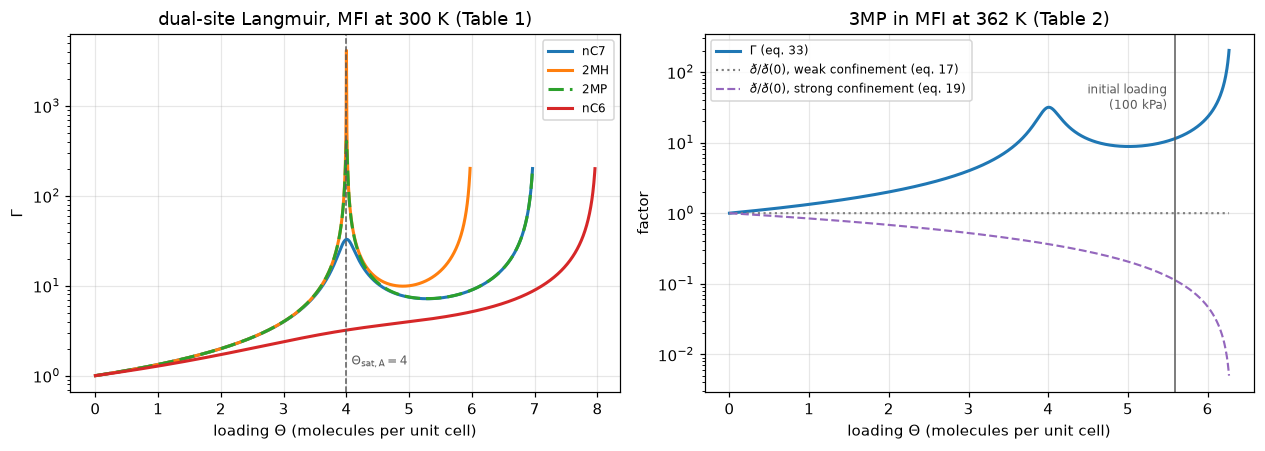

Between the two ends of the review's 3MP desorption problem, Theta = 0.093 and 5.596,
Gamma goes 1.024 -> 31.6 (max, at Theta = 4.007) -> 8.80 (min, at Theta = 5.011) -> 11.44.
So the Fick diffusivity swings by a factor of 30.9 inside a single desorption,
while the M-S diffusivity changes by at most a factor of 8.95 even under
the strong-confinement scenario.


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.2))
# nC7 and 2MP lie on top of each other below Theta = 4, so line style marks them too
for comp, tab, col, ls in (("nC7", "Table 1", "tab:blue", "-"),
                           ("2MH", "Table 1", "tab:orange", "-"),
                           ("2MP", "Table 1", "tab:green", (0, (5, 2))),
                           ("nC6", "Table 1", "tab:red", "-")):
    iso = iso_of(comp, tab)
    Th = np.linspace(1e-3, 0.995 * iso.Th_sat, 4000)
    axes[0].semilogy(Th, iso.Gamma(Th), lw=2.0, color=col, ls=ls, label=comp)
axes[0].axvline(4.0, color="0.35", lw=1.0, ls="--")
axes[0].annotate(r"$\Theta_{\rm sat,A}=4$", (4.08, 1.3), fontsize=8, color="0.35")
axes[0].set(xlabel=r"loading $\Theta$ (molecules per unit cell)",
            ylabel=r"$\Gamma$", title="dual-site Langmuir, MFI at 300 K (Table 1)")
axes[0].legend(fontsize=8)

Th = np.linspace(1e-3, 0.995 * mp3.Th_sat, 1200)
axes[1].semilogy(Th, mp3.Gamma(Th), lw=2.0, color="tab:blue", label=r"$\Gamma$ (eq. 33)")
axes[1].semilogy(Th, np.ones_like(Th), lw=1.4, color="tab:gray", ls=":",
                 label=r"$\eth/\eth(0)$, weak confinement (eq. 17)")
axes[1].semilogy(Th, 1 - Th / mp3.Th_sat, lw=1.4, color="tab:purple", ls="--",
                 label=r"$\eth/\eth(0)$, strong confinement (eq. 19)")
axes[1].axvline(Th_0, color="0.35", lw=1.0)
axes[1].annotate("initial loading\n(100 kPa)", (Th_0 - 0.1, 30), fontsize=8, ha="right", color="0.35")
axes[1].set(xlabel=r"loading $\Theta$ (molecules per unit cell)", ylabel="factor",
            title="3MP in MFI at 362 K (Table 2)")
axes[1].legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

G_s, G_0 = float(mp3.Gamma(Th_s)), float(mp3.Gamma(Th_0))
print(f"Between the two ends of the review's 3MP desorption problem, Theta = {Th_s:.3f} and {Th_0:.3f},")
print(f"Gamma goes {G_s:.3f} -> {DS['mp3_gamma_max']:.1f} (max, at Theta = {DS['mp3_theta_at_gamma_max']:.3f})"
      f" -> {DS['mp3_gamma_min']:.2f} (min, at Theta = {DS['mp3_theta_at_gamma_min']:.3f}) -> {G_0:.2f}.")
print(f"So the Fick diffusivity swings by a factor of {DS['mp3_gamma_swing']:.1f} inside a single desorption,")
print(f"while the M-S diffusivity changes by at most a factor of {DS['mp3_ms_swing_strong']:.2f} even under")
print("the strong-confinement scenario.")

### 4. The question the case is about

The claim under test is that the Maxwell–Stefan diffusivity is far less
loading-dependent than the Fick one, and that the difference is $\Gamma$. The
second half is a definition, eq. (14), and cannot fail. The first half is a
claim, and the review's own two scenarios settle it in opposite directions.

In [12]:
def swing(x):
    return float(np.max(x) / np.min(x))


def swing_study(theta_max=0.9):
    """Loading swings of D_MS and D_Fick under eqs. (17)-(20), Langmuir Gamma, 0 <= theta <= theta_max."""
    theta = np.linspace(0.0, theta_max, 10)
    weak_ms, weak_f = np.ones_like(theta), 1.0 / (1.0 - theta)          # eqs. (17), (18)
    strong_ms, strong_f = 1.0 - theta, np.ones_like(theta)              # eqs. (19), (20)
    return {"swing_weak_advantage": swing(weak_f) / swing(weak_ms),
            "swing_strong_advantage": swing(strong_ms) / swing(strong_f),
            "swing_reciprocal_gap": float(np.max(np.abs(weak_f * strong_ms - 1.0))),
            "_theta_max": theta_max}


SW = swing_study()
print(f"Over 0 <= theta <= {SW['_theta_max']:g}, with the Langmuir Gamma = 1/(1-theta):\n")
print(f"{'scenario':>22}{'less loading-dependent':>26}{'by a factor':>13}")
print(f"{'weak confinement':>22}{'the M-S one':>26}{SW['swing_weak_advantage']:13.1f}")
print(f"{'strong confinement':>22}{'the FICK one':>26}{SW['swing_strong_advantage']:13.1f}")
print("\nSame factor, opposite direction. 'The M-S diffusivity is the loading-independent one' is not")
print("a property of the M-S formulation; it is the review's eq. (17), an empirical statement about")
print("weakly confined guests, and the review states eq. (19) for CF4, SF6 and 2MH in the next paragraph")
print("of Section 2.1, contrasting the two explicitly at the end of 2.1 and again in 2.3.")
print(f"\nThe two factors are EXACTLY reciprocal (at most 1e-15, here {SW['swing_reciprocal_gap']:.1e}):")
print("Gamma = 1/(1-theta) and eq. (19)'s eth = (1-theta) are inverses, so the two swings are equal over")
print(f"any loading range, and the size of the factor is 1/(1 - theta_max) = {1 / (1 - SW['_theta_max']):.0f},")
print("set by the range chosen. What is not forced is the DIRECTION, which flips between the two scenarios.")
print("\nWhat survives both scenarios: only Gamma diverges.")
print(f"{'theta':>8}{'Gamma':>10}{'D_MS weak':>12}{'D_MS strong':>13}")
for t in (0.5, 0.9, 0.99, 0.999):
    print(f"{t:8.3f}{1 / (1 - t):10.1f}{1.0:12.1f}{1 - t:13.4f}")
print("Gamma is unbounded; the M-S diffusivity is bounded in both scenarios (by eth(0) above and 0 below).")

Over 0 <= theta <= 0.9, with the Langmuir Gamma = 1/(1-theta):

              scenario    less loading-dependent  by a factor
      weak confinement               the M-S one         10.0
    strong confinement              the FICK one         10.0

Same factor, opposite direction. 'The M-S diffusivity is the loading-independent one' is not
a property of the M-S formulation; it is the review's eq. (17), an empirical statement about
weakly confined guests, and the review states eq. (19) for CF4, SF6 and 2MH in the next paragraph
of Section 2.1, contrasting the two explicitly at the end of 2.1 and again in 2.3.

The two factors are EXACTLY reciprocal (at most 1e-15, here 0.0e+00):
Gamma = 1/(1-theta) and eq. (19)'s eth = (1-theta) are inverses, so the two swings are equal over
any loading range, and the size of the factor is 1/(1 - theta_max) = 10,
set by the range chosen. What is not forced is the DIRECTION, which flips between the two scenarios.

What survives both scenarios: only Gam

### 5. The uptake problem

Now the transient sphere. The review solves eqs. (25) to (27) twice: once for a
constant Fick diffusivity, where eq. (30) applies, and once with the strongly
non-linear eq. (18), where it does not. The time-averaged Sherwood number at
$F = 0.75$ is the Fourier number where the solved mean uptake reaches 0.75, a
root on the model, put into eq. (31).

In [13]:
FO_STAR = PRINTED["fo_asymmetry"]
THETA_S = (0.3, 0.6, 0.9)
FO_OUT = np.unique(np.append(FO, FO_STAR))
I_STAR = int(np.flatnonzero(FO_OUT == FO_STAR)[0])


def weak_D(theta):
    """Eq. (18): D/eth(0) = 1/(1 - theta), weak confinement with a Langmuir isotherm."""
    return 1.0 / (1.0 - theta)


def sh_at(fo, F):
    """Eq. (31) at a Fourier number and an uptake."""
    return float(sherwood(fo, 1.0 - F))


SH_EXT_THETA = (0.3, 0.9)      # the two curves whose Sh at F = 0.75 the text reports
SH_KS, SH_NS = (1, 2, 4, 8), (1, 2, 4)      # step ladder (s/k), cell ladder (n_r * m)


def sh75_extrapolated(D, th, n_r, s):
    """Sh at F = 0.75 extrapolated in step and in cell size, from successive ladders.

    The two corrections are added (the other axis's error cancels in successive
    differences). Returns the extrapolated value, the production value and the
    extrapolation's own remainder: the shift of the step extrapolation between the
    finest and the coarser triple of the ladder.
    """
    def sh(n, sc):
        c = Crystal(D, n_r=n, tol=TOL, upper=1.0 if callable(D) else None)
        return sh_at(c.fo_at_mean(0.0, th, 0.75 * th, 1.0, s=sc), 0.75)

    st = observed_orders(lambda k: sh(n_r, s / k), SH_KS)
    sp = observed_orders(lambda m: sh(n_r * m, s), SH_NS)
    base = st["values"][0]
    v = st["values"]
    coarse = v[2] + (v[2] - v[1]) / (2.0 ** st["orders"][0] - 1.0)
    return {"ext": st["extrapolated"] + sp["extrapolated"] - base, "prod": base,
            "remainder": abs(st["extrapolated"] - coarse), "orders": (st["orders"], sp["orders"])}


def weak_study(D=weak_D, n_r=N_R, s=1.0, resolved=None, theta_s=THETA_S):
    """Uptake and release under eq. (18) for each surface occupancy theta_s."""
    out, curves = {}, {}
    sh75, prod_err = [], []
    for th in theta_s:
        c = Crystal(D, n_r=n_r, tol=TOL, upper=1.0 if callable(D) else None)
        if th in SH_EXT_THETA:
            e = sh75_extrapolated(D, th, n_r, s)
            key = f"{th:g}".replace(".", "")
            out[f"sh75_weak_{key}_ext"] = e["ext"]
            out[f"_sh75_ext_remainder_{key}"] = e["remainder"]
            out[f"_sh75_ext_orders_{key}"] = e["orders"]
            prod_err.append(abs(e["prod"] / e["ext"] - 1.0))
        ads = c.run(0.0, th, FO_OUT, s=s)[0] / th
        des = (th - c.run(th, 1e-9, FO_OUT, s=s)[0]) / th
        fo75 = c.fo_at_mean(0.0, th, 0.75 * th, 1.0, s=s)
        sh75.append(sh_at(fo75, 0.75))
        out[f"sh75_weak_{th:g}".replace(".", "")] = sh75[-1]
        if resolved is not None:
            fo_r = c.fo_at_mean(0.0, th, (1.0 - resolved) * th, 3.0, s=s)
            out[f"sh_resolved_over_asymptote_{th:g}".replace(".", "")] = sh_at(fo_r, 1.0 - resolved) / (
                2 * np.pi ** 2 / 3 / (1 - th))
            out[f"_fo_resolved_{th:g}"] = fo_r
        curves[th] = (ads, des)
    out["weak_asymmetry_pp_09"] = 100 * (curves[0.9][0][I_STAR] - curves[0.9][1][I_STAR])
    out["_sh_rises"] = np.diff(sh75)
    out["sh75_production_rel_err"] = max(prod_err)
    out["_curves"] = curves
    return out

The threshold below which eq. (31) reads the solver rather than the physics is
the production time-integration error, measured in *Validation* (cell size and
step refined on separate ladders against eq. 30). Eq. (31) contains
$\ln(1-F)$, so where $1-F$ is no larger than that error the Sherwood number is
not resolved; the "resolved" Sherwood number of each curve is taken at the
Fourier number where $1-F$ equals it, a root on the model.

In [14]:
@lru_cache(maxsize=None)
def _const_F(n, k, nu, fo, dt0_only):
    """Constant-D uptake at fo on n cells, step schedule refined k times; and its round-off floor."""
    c = Crystal(1.0, n_r=n, nu=nu)
    kw = dict(dt0=5e-6 / k) if dt0_only else dict(s=1.0 / k)
    return float(c.run(0.0, 1.0, [fo], **kw)[0][0]), c.floor


def const_ladder_study(nu=2, ns=(25, 50, 100, 200), ks=(1, 2, 4, 8), fo=0.05, dt0_only=False):
    """Constant-D uptake at Fo = fo against eq. (30), extrapolated in cell size and in step.

    The cell-size ladder runs at the finest step and the step ladder on the finest
    grid, so along each ladder the other axis's error is fixed and cancels in
    successive differences; the two corrections are added. ``dt0_only`` scales
    only the initial step of the schedule.
    """
    def F(n, k):
        return _const_F(n, k, nu, fo, dt0_only)

    ref = float(series_F(fo, N_TERMS)[0])
    sp = observed_orders(lambda n: F(n, ks[-1])[0], ns)
    st = observed_orders(lambda k: F(ns[-1], k)[0], ks)
    base, floor = F(ns[-1], ks[-1])
    ext = sp["extrapolated"] + st["extrapolated"] - base
    prod = F(N_R, 1)[0]
    vs, vt = np.array(sp["values"]), np.array(st["values"])
    return {"space_observed_order": sp["orders"][-1], "dt_observed_order": st["orders"][-1],
            "space_ladder_over_roundoff": abs(vs[-1] - vs[-2]) / floor,
            "dt_ladder_over_roundoff": abs(vt[-1] - vt[-2]) / floor,
            "dt_refined_rel_err": abs(base - ref) / ref,
            "space_refined_rel_err": abs(st["extrapolated"] - ref) / ref,
            "ext_both_vs_series": abs(ext - ref) / ref,
            "production_rel_err": abs(prod - ref) / ref,
            "_ladders": (ns, sp, ks, st), "_ref": ref, "_ext": ext}


CL = const_ladder_study()
RESOLVED = CL["production_rel_err"]
print(f"production time-integration error (constant D, {N_R} cells, Fo = 0.05): "
      f"{RESOLVED:.2e} of F, the resolution limit of eq. (31) below")

WK = weak_study(resolved=RESOLVED)
c0 = Crystal(1.0, n_r=N_R)
F_const = c0.run(0.0, 1.0, FO_OUT)[0]
SH75_CONST = sh_at(c0.fo_at_mean(0.0, 1.0, 0.75, 1.0), 0.75)
print(f"\n{'theta_s':>10}{'Sh at F=0.75':>14}{'F at Fo=0.04':>14}{'F_des at Fo=0.04':>18}")
for th in THETA_S:
    a, d = WK["_curves"][th]
    print(f"{th:10.2f}{WK[f'sh75_weak_{th:g}'.replace('.', '')]:14.2f}{a[I_STAR]:14.4f}{d[I_STAR]:18.4f}")
print(f"{'constant D':>10}{SH75_CONST:14.3f}{F_const[I_STAR]:14.4f}{'(symmetric)':>18}")
print("\nThe review states that with the non-linear eq. (18) 'the Sh number can be significantly higher")
print(f"than 10'. Measured: {WK['sh75_weak_03']:.1f} to {WK['sh75_weak_09']:.1f}, rising with theta_s, "
      f"against {SH75_CONST:.2f} at constant D.")
print("The production values read low; extrapolated in step (ladder 1, 1/2, 1/4, 1/8) and in cell size")
print(f"(ladder {SH_NS[0] * N_R}, {SH_NS[1] * N_R}, {SH_NS[2] * N_R} cells), the corrections added:")
for key in ("03", "09"):
    so, po = WK[f"_sh75_ext_orders_{key}"]
    print(f"  theta_s = 0.{key[1]}: Sh = {WK[f'sh75_weak_{key}_ext']:.3f} (production {WK[f'sh75_weak_{key}']:.3f}); "
          f"observed orders in step {so[-1]:.3f}, in cell size {po[-1]:.3f}; "
          f"the step extrapolation moves by {WK[f'_sh75_ext_remainder_{key}']:.1e} between its two ladder triples")
print(f"The production curves read the Sherwood number low by at most {WK['sh75_production_rel_err'] * 100:.2f} %.")
print("It also states that adsorption and desorption are asymmetric; at Fo = 0.04 and theta_s = 0.9 the")
print(f"two differ by {WK['weak_asymmetry_pp_09']:.1f} percentage points of F.")

production time-integration error (constant D, 150 cells, Fo = 0.05): 1.54e-03 of F, the resolution limit of eq. (31) below



   theta_s  Sh at F=0.75  F at Fo=0.04  F_des at Fo=0.04
      0.30         12.75        0.6083            0.5803
      0.60         18.00        0.6885            0.6116
      0.90         35.83        0.8610            0.6566
constant D        10.025        0.5562       (symmetric)

The review states that with the non-linear eq. (18) 'the Sh number can be significantly higher
than 10'. Measured: 12.8 to 35.8, rising with theta_s, against 10.02 at constant D.
The production values read low; extrapolated in step (ladder 1, 1/2, 1/4, 1/8) and in cell size
(ladder 150, 300, 600 cells), the corrections added:
  theta_s = 0.3: Sh = 12.818 (production 12.754); observed orders in step 0.978, in cell size 1.817; the step extrapolation moves by 9.5e-05 between its two ladder triples
  theta_s = 0.9: Sh = 35.980 (production 35.835); observed orders in step 0.978, in cell size 1.699; the step extrapolation moves by 3.7e-04 between its two ladder triples
The production curves read the Sherwood n

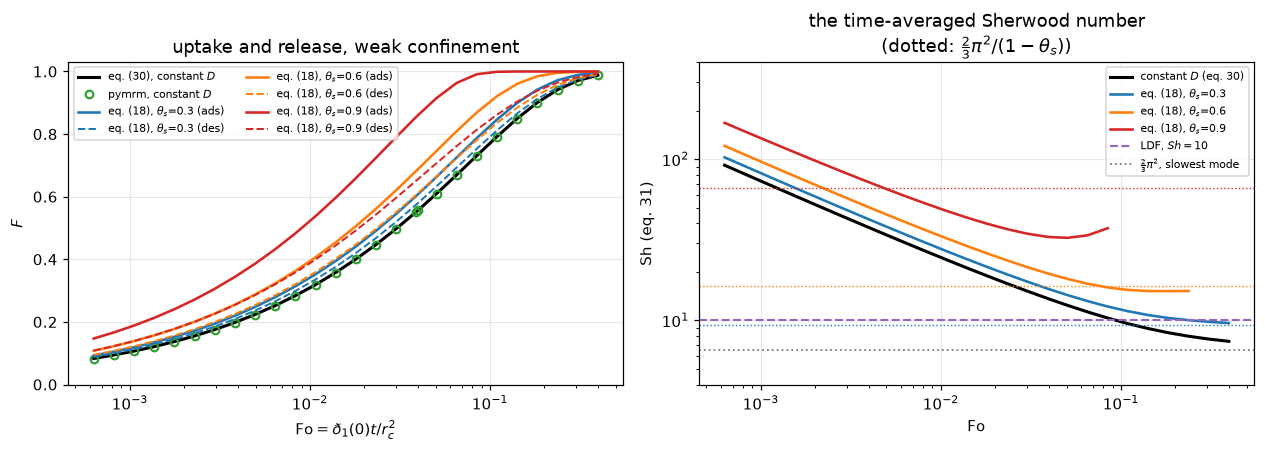

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.2))
axes[0].semilogx(FO_OUT, series_F(FO_OUT), color="k", lw=2.0, label="eq. (30), constant $D$")
axes[0].plot(FO_OUT, F_const, "o", ms=5, mfc="none", mew=1.4, color="tab:green", label="pymrm, constant $D$")
for th, col in zip(THETA_S, ("tab:blue", "tab:orange", "tab:red")):
    a, d = WK["_curves"][th]
    axes[0].semilogx(FO_OUT, a, color=col, lw=1.7, label=fr"eq. (18), $\theta_s$={th} (ads)")
    axes[0].semilogx(FO_OUT, d, color=col, lw=1.3, ls="--", label=fr"eq. (18), $\theta_s$={th} (des)")
axes[0].set(xlabel=r"$\mathrm{Fo}=\eth_1(0)t/r_c^2$", ylabel="$F$", ylim=(0, 1.03),
            title="uptake and release, weak confinement")
axes[0].legend(fontsize=7, loc="upper left", ncol=2)

axes[1].loglog(FO_OUT, sherwood(FO_OUT, series_one_minus_F(FO_OUT)), color="k", lw=2.0,
               label="constant $D$ (eq. 30)")
for th, col in zip(THETA_S, ("tab:blue", "tab:orange", "tab:red")):
    a = WK["_curves"][th][0]
    m = (1.0 - a) > RESOLVED
    axes[1].loglog(FO_OUT[m], sherwood(FO_OUT[m], 1.0 - a[m]), color=col, lw=1.7,
                   label=fr"eq. (18), $\theta_s$={th}")
    axes[1].axhline(2 * np.pi ** 2 / 3 / (1 - th), color=col, lw=0.9, ls=":")
axes[1].axhline(10.0, color="tab:purple", lw=1.4, ls="--", label="LDF, $Sh=10$")
axes[1].axhline(2 * np.pi ** 2 / 3, color="tab:gray", lw=1.2, ls=":",
                label=r"$\frac{2}{3}\pi^2$, slowest mode")
axes[1].set(xlabel=r"$\mathrm{Fo}$", ylabel=r"$\mathrm{Sh}$ (eq. 31)", ylim=(4, 400),
            title="the time-averaged Sherwood number\n(dotted: $\\frac{2}{3}\\pi^2/(1-\\theta_s)$)")
axes[1].legend(fontsize=7)
fig.tight_layout()
plt.show()

The final relaxation is governed by the Fick diffusivity at the final loading,
so under eq. (18) the Sherwood number should approach
$\tfrac{2}{3}\pi^2/(1-\theta_s)$ rather than $\tfrac{2}{3}\pi^2$. That is a
prediction the computed curves could miss, so it is measured at the resolution
limit, together with the constant-$D$ control, which approaches its own limit
as $\tfrac{2}{3}(\pi^2 + \ln(\pi^2/6)/\mathrm{Fo})$.

In [16]:
fo_res_const = one_root(lambda f: float(series_one_minus_F(f, N_TERMS)[0]) - RESOLVED, 0.01, 5.0,
                        "constant-D resolution", xtol=1e-15)
SH_RES_CONST = sh_at(fo_res_const, 1.0 - RESOLVED) / (2 * np.pi ** 2 / 3)
print(f"Sh at the resolution limit 1 - F = {RESOLVED:.2e}, over (2/3) pi^2 / (1 - theta_s):")
print(f"{'theta_s':>10}{'asymptote':>11}{'Fo there':>10}{'Sh there':>10}{'ratio':>8}")
for th in THETA_S:
    asym = 2 * np.pi ** 2 / 3 / (1 - th)
    r = WK[f"sh_resolved_over_asymptote_{th:g}".replace(".", "")]
    print(f"{th:10.2f}{asym:11.2f}{WK[f'_fo_resolved_{th:g}']:10.3f}{r * asym:10.2f}{r:8.3f}")
print(f"{'constant D':>10}{2 * np.pi ** 2 / 3:11.2f}{fo_res_const:10.3f}"
      f"{SH_RES_CONST * 2 * np.pi ** 2 / 3:10.2f}{SH_RES_CONST:8.3f}")
print("\nNone of these is AT its asymptote, and the constant-D row says why: at that Fourier number eq. (31)")
print(f"still reads {(SH_RES_CONST - 1) * 100:.1f} % high from the ln(pi^2/6)/Fo term. Against that offset the theta_s")
print(f"= 0.3 and 0.6 curves sit at {WK['sh_resolved_over_asymptote_03']:.3f} and "
      f"{WK['sh_resolved_over_asymptote_06']:.3f} of theirs; the 0.9 curve at "
      f"{WK['sh_resolved_over_asymptote_09']:.3f}, still climbing where")
print("the resolution limit stops it. So this check establishes the DIRECTION and the scale, Sh growing with")
print("theta_s roughly as 1/(1 - theta_s), and not the limit itself.")

Sh at the resolution limit 1 - F = 1.54e-03, over (2/3) pi^2 / (1 - theta_s):
   theta_s  asymptote  Fo there  Sh there   ratio
      0.30       9.40     0.452      9.56   1.017
      0.60      16.45     0.283     15.26   0.928
      0.90      65.80     0.105     41.19   0.626
constant D       6.58     0.606      7.13   1.083

None of these is AT its asymptote, and the constant-D row says why: at that Fourier number eq. (31)
still reads 8.3 % high from the ln(pi^2/6)/Fo term. Against that offset the theta_s
= 0.3 and 0.6 curves sit at 1.017 and 0.928 of theirs; the 0.9 curve at 0.626, still climbing where
the resolution limit stops it. So this check establishes the DIRECTION and the scale, Sh growing with
theta_s roughly as 1/(1 - theta_s), and not the limit itself.


### 6. The 3MP desorption

The review's Section 2.4 example, run with its own DSL isotherm: a crystal
equilibrated at 100 kPa and then exposed to 0.5 Pa, and the same problem
reversed. The Fick diffusivity is $\eth\Gamma$ and $\Gamma$ swings strongly over
the loading range (section 2), so this is where the non-linearity is at its
most violent.

The review does not say what the loading dependence of $\eth$ is for 3MP, so
both of its scenarios are run and the difference is reported.

In [17]:
FO2_OUT = np.unique(np.append(FO2, FO_STAR))
I2_STAR = int(np.flatnonzero(FO2_OUT == FO_STAR)[0])


def mp3_scenarios(iso, gamma=True):
    """D/eth(0) for 3MP under eq. (17) and eq. (19); gamma=False drops Gamma."""
    G = (lambda Th: iso.Gamma(Th)) if gamma else (lambda Th: np.ones_like(Th))
    return {"eq17": lambda Th: G(Th), "eq19": lambda Th: (1 - Th / iso.Th_sat) * G(Th)}


def mp3_study(gamma=True, n_r=N_R, s=1.0, tol=TOL, row=("3MP", "Table 2")):
    """Adsorption and desorption between the loadings at 0.5 Pa and 100 kPa, both scenarios.

    ``row`` is the isotherm row: the 3MP row of Table 2, as the review's example.
    """
    iso = iso_of(*row)
    Th_0, Th_s = float(iso.theta(P_INITIAL)), float(iso.theta(P_SURFACE))
    out, runs = {}, {}
    for lab, D in mp3_scenarios(iso, gamma).items():
        c = Crystal(D, n_r=n_r, tol=tol, upper=iso.Th_sat)
        ads = (c.run(Th_s, Th_0, FO2_OUT, s=s)[0] - Th_s) / (Th_0 - Th_s)
        m, prof = c.run(Th_0, Th_s, FO2_OUT, s=s)
        des = (m - Th_0) / (Th_s - Th_0)
        Fa, Fd = ads[I2_STAR], des[I2_STAR]
        c.run(Th_0, Th_s, [FO2[-1]], s=s, keep_rates=True)   # untruncated steps to the last Fo
        rates = -np.array(c.rates)                    # desorption rate at every step
        inc = np.diff(rates) / rates[1:]              # relative change from step to step
        out[f"mp3_F_ads_{lab}"], out[f"mp3_F_des_{lab}"] = Fa, Fd
        out[f"_inc_{lab}"] = inc
        runs[lab] = (ads, des, prof)
    out["mp3_asymmetry_gap_min"] = min(out[f"mp3_F_ads_{k}"] - out[f"mp3_F_des_{k}"] for k in runs)
    out["_rate_inc"] = np.concatenate([out["_inc_eq17"], out["_inc_eq19"]])
    out["_runs"] = runs
    return out


MP = mp3_study()
print(f"The review: 'at Fo = {FO_STAR:g} the adsorption process is nearly at equilibrium whereas the")
print("desorption process has still a long way to go to equilibration.'\n")
print(f"{'assumption about eth':>34}{'F_ads':>9}{'F_des':>9}{'gap':>9}")
for k, lab in (("eq17", "eth constant (eq. 17)"), ("eq19", "eth = eth(0)(1-theta) (eq. 19)")):
    a, d = MP[f"mp3_F_ads_{k}"], MP[f"mp3_F_des_{k}"]
    print(f"{lab:>34}{a:9.4f}{d:9.4f}{a - d:9.4f}")
print("\nThe statement holds under both, so it does not depend on the assumption the review leaves")
print("unstated. It is a feature of Gamma, not of a fitted eth.")
print("\nFig. 10(a) is described as showing 'an inflection in the desorption kinetics, indicated by the")
print(f"arrow'. The desorption rate, at every backward-Euler step up to Fo = {FO2[-1]:.2f}, under both scenarios:")
n_up = int(np.sum(MP["_rate_inc"] > 0))
print(f"   steps where the rate rises: {n_up} of {MP['_rate_inc'].size}; smallest relative fall "
      f"{np.min(np.abs(MP['_rate_inc'])):.1e} per step")
print("A monotone rate: no interior maximum. The page cannot settle the figure: the claim lives in a")
print("figure that is not digitised, and a monotone rate is what both stated scenarios give.")

The review: 'at Fo = 0.04 the adsorption process is nearly at equilibrium whereas the
desorption process has still a long way to go to equilibration.'

              assumption about eth    F_ads    F_des      gap
             eth constant (eq. 17)   0.9850   0.7514   0.2335
    eth = eth(0)(1-theta) (eq. 19)   0.7846   0.6710   0.1136

The statement holds under both, so it does not depend on the assumption the review leaves
unstated. It is a feature of Gamma, not of a fitted eth.

Fig. 10(a) is described as showing 'an inflection in the desorption kinetics, indicated by the
arrow'. The desorption rate, at every backward-Euler step up to Fo = 0.50, under both scenarios:
   steps where the rate rises: 0 of 898; smallest relative fall 3.5e-03 per step
A monotone rate: no interior maximum. The page cannot settle the figure: the claim lives in a
figure that is not digitised, and a monotone rate is what both stated scenarios give.


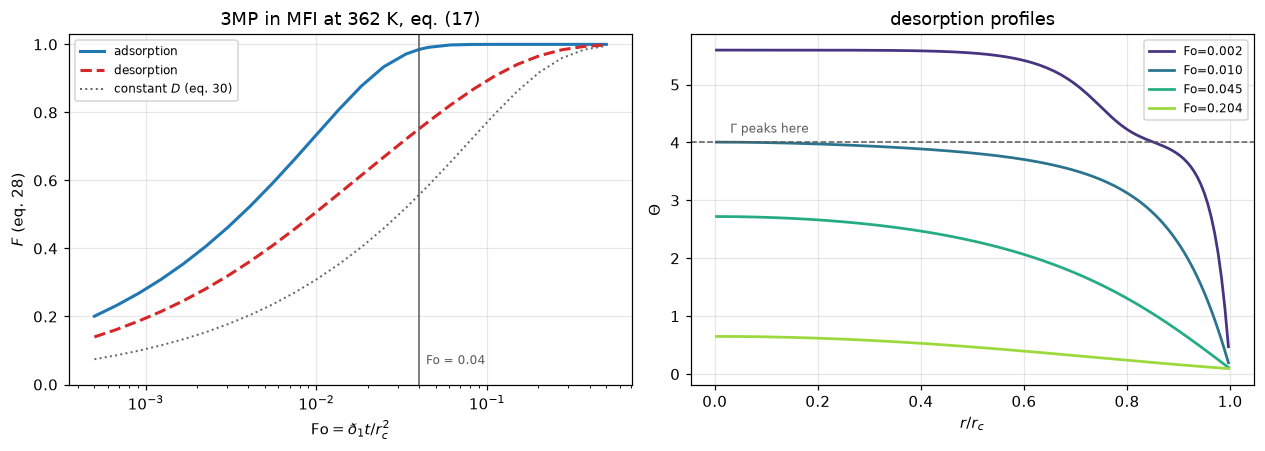

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.2))
Fa, Fd, prof = MP["_runs"]["eq17"]
axes[0].semilogx(FO2_OUT, Fa, color="tab:blue", lw=2.0, label="adsorption")
axes[0].semilogx(FO2_OUT, Fd, color="tab:red", lw=2.0, ls="--", label="desorption")
axes[0].semilogx(FO2, series_F(FO2), color="0.4", lw=1.3, ls=":", label="constant $D$ (eq. 30)")
axes[0].axvline(FO_STAR, color="0.35", lw=1.0)
axes[0].annotate(f"Fo = {FO_STAR:g}", (FO_STAR * 1.1, 0.06), fontsize=8, color="0.35")
axes[0].set(xlabel=r"$\mathrm{Fo}=\eth_1 t/r_c^2$", ylabel="$F$ (eq. 28)", ylim=(0, 1.03),
            title="3MP in MFI at 362 K, eq. (17)")
axes[0].legend(fontsize=8, loc="upper left")
r_c = Crystal(1.0, n_r=N_R).r_c
for fo, col in zip((FO2[4], FO2[10], FO2[15], FO2[20]), plt.cm.viridis(np.linspace(0.15, 0.85, 4))):
    axes[1].plot(r_c, prof[float(fo)], color=col, lw=1.8, label=fr"Fo={fo:.3f}")
axes[1].axhline(DS["mp3_theta_at_gamma_max"], color="0.35", lw=1.0, ls="--")
axes[1].annotate(r"$\Gamma$ peaks here", (0.03, DS["mp3_theta_at_gamma_max"] + 0.15), fontsize=8,
                 color="0.35")
axes[1].set(xlabel="$r/r_c$", ylabel=r"$\Theta$", title="desorption profiles")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

### 7. The one place the review prints a flux

Section 4.1 permeates single components across an MFI membrane and prints two
steady-state fluxes. This is the only number in the review produced by the
single-component flux law itself, but **the membrane thickness is never
printed**, so an absolute flux cannot be computed. The *ratio* can: $\delta$ and
the framework density cancel out of it exactly.

Integrating eq. (12) across a membrane at steady state with constant $\eth$,

$$N_1\delta = \rho\,\eth_1\!\int_{p_\delta}^{p_0}\!\Theta_1^0(p)\,\frac{\mathrm{d}p}{p}
= \rho\,\eth_1\left[\Theta_{\mathrm{sat},A}\ln(1+b_Ap_0)
+ \Theta_{\mathrm{sat},B}\ln(1+b_Bp_0)\right]$$

with the downstream side swept to zero. That integral is the one eq. (64)
calls the surface potential, which is why the code reuses it.

In [19]:
N_A = 6.02214076e23                    # 1/mol
M_SI, M_O = 28.0855, 15.999            # g/mol


def membrane_study(gamma=True, swap_D=False, printed=None, o_per_si=2):
    """The C1/nC4 permeation flux ratio and the membrane thickness it implies."""
    pr = {**PRINTED, **(printed or {})}
    iC1, iC4 = iso_of("C1", "Table 1"), iso_of("nC4", "Table 1")
    D1, D4 = params("C1", "Section 4.1")["D_MS"], params("nC4", "Section 4.1")["D_MS"]
    if swap_D:
        D1, D4 = D4, D1
    drive = (lambda iso, p: float(iso.surface_potential(p))) if gamma else (lambda iso, p: float(iso.theta(p)))
    s1, s4 = D1 * drive(iC1, pr["p0_C1"]), D4 * drive(iC4, pr["p0_nC4"])
    ratio, ratio_pr = s1 / s4, pr["flux_C1"] / pr["flux_nC4"]
    no_gamma = (D1 * float(iC1.theta(pr["p0_C1"]))) / (D4 * float(iC4.theta(pr["p0_nC4"])))
    m_cell = (96 * M_SI + 96 * o_per_si * M_O) / N_A * 1e-3      # kg per MFI unit cell, Si96O192
    rho_uc = pr["rho_MFI"] / m_cell                               # unit cells per m3
    d1 = rho_uc * s1 / N_A / (pr["flux_C1"] * 1e-3)
    d4 = rho_uc * s4 / N_A / (pr["flux_nC4"] * 1e-3)
    allow = (half_unit(PRINTED_AS["flux_C1"]) / pr["flux_C1"]
             + half_unit(PRINTED_AS["flux_nC4"]) / pr["flux_nC4"])
    sp = (pr["flux_nC4"] / pr["flux_C1"]) * (pr["p0_C1"] / pr["p0_nC4"])
    dev = ratio / ratio_pr - 1
    return {"flux_ratio_rel_dev": dev, "flux_ratio_over_rounding": abs(dev) / allow,
            "flux_ratio_gamma_lever": no_gamma / ratio,
            "delta_reconstructed_um": d1 * 1e6,
            "delta_spread_identity": abs((d1 / d4 - 1) - dev),
            "sp_pure_rel_dev": sp / pr["sp_pure"] - 1,
            "_ratio": (ratio, ratio_pr, no_gamma, d4 * 1e6, sp)}


MB = membrane_study()
ratio, ratio_pr, no_gamma, d4, sp = MB["_ratio"]
print(f"  N_C1 / N_nC4 from eqs. (12), (15), (32) : {ratio:.3f}")
print(f"  from the review's printed fluxes        : {ratio_pr:.3f}")
print(f"  deviation                               : {MB['flux_ratio_rel_dev'] * 100:+.2f} %, "
      f"{MB['flux_ratio_over_rounding']:.2f} of the rounding allowance of two-figure fluxes")
print(f"\n  the same ratio with Gamma dropped       : {no_gamma:.3f}   "
      f"({MB['flux_ratio_gamma_lever']:.2f}x away)")
print("  So this check has real power over the thermodynamic factor: it is not an identity.")
print(f"\n  The unprinted membrane thickness from each flux, with the review's rho = "
      f"{PRINTED['rho_MFI']:.0f} kg/m3:")
print(f"     from the C1 flux  : {MB['delta_reconstructed_um']:.2f} um")
print(f"     from the nC4 flux : {d4:.2f} um")
print("  The value is new, the agreement is not: the ratio of the two thicknesses is the flux-ratio check")
print(f"  inverted (equal to it within 1e-12, here {MB['delta_spread_identity']:.0e}). One check, not two.")
print(f"\n  eq. (60) on the printed fluxes gives S_P = {sp:.3f} against the review's printed "
      f"{PRINTED_AS['sp_pure']} ({MB['sp_pure_rel_dev'] * 100:+.2f} %),")
print("  arithmetic on two printed numbers that tests nothing beyond the transcription.")

  N_C1 / N_nC4 from eqs. (12), (15), (32) : 10.949
  from the review's printed fluxes        : 10.968
  deviation                               : -0.17 %, 0.06 of the rounding allowance of two-figure fluxes

  the same ratio with Gamma dropped       : 40.821   (3.73x away)
  So this check has real power over the thermodynamic factor: it is not an identity.

  The unprinted membrane thickness from each flux, with the review's rho = 1800 kg/m3:
     from the C1 flux  : 39.97 um
     from the nC4 flux : 40.04 um
  The value is new, the agreement is not: the ratio of the two thicknesses is the flux-ratio check
  inverted (equal to it within 1e-12, here 0e+00). One check, not two.

  eq. (60) on the printed fluxes gives S_P = 1.732 against the review's printed 1.73 (+0.14 %),
  arithmetic on two printed numbers that tests nothing beyond the transcription.


## Validation

Everything on this page is **reproduction**: the targets are the authors' own
computed output, not measurements. The review does contain experimental data
(Garg & Ruthven's ethane uptake, Shah's benzene diffusivities, Millot's
Arrhenius data) but all of it is in figures, none of it is digitised here, and no
claim below rests on any of it.

The solver first: the constant-$D$ crystal against the exact series eq. (30),
with the cell-size and step errors measured on separate ladders, and then the
same ladders on the hardest non-linear problem on the page, the 3MP desorption
under eq. (17).

In [20]:
ns, sp_, ks, st_ = CL["_ladders"]
print(f"1. constant D, F(Fo = 0.05) against eq. (30) = {CL['_ref']:.9f}")
print("   cells " + " ".join(f"{n:>11d}" for n in ns) + "   (at the finest step)")
print("         " + " ".join(f"{v:11.8f}" for v in sp_["values"]) + "   orders "
      + " ".join(f"{o:.3f}" for o in sp_["orders"]))
print("   step  " + " ".join(f"{'1/' + str(k):>11}" for k in ks) + f"   (on {ns[-1]} cells)")
print("         " + " ".join(f"{v:11.8f}" for v in st_["values"]) + "   orders "
      + " ".join(f"{o:.3f}" for o in st_["orders"]))
print(f"   observed order in step {CL['dt_observed_order']:.3f} (backward Euler: 1), in cell size "
      f"{CL['space_observed_order']:.3f} (2)")
print(f"   finest successive differences over the round-off floor: step "
      f"{CL['dt_ladder_over_roundoff']:.1e}, cell size {CL['space_ladder_over_roundoff']:.1e}")
print(f"   finest level against eq. (30): {CL['dt_refined_rel_err']:.2e}; extrapolated in step only "
      f"(the spatial error at {ns[-1]} cells): about 1e-5 (here {CL['space_refined_rel_err']:.1e})")
print(f"   extrapolated in both against eq. (30): at most 1e-5 (here {CL['ext_both_vs_series']:.1e})")
print(f"   production level ({N_R} cells, s = 1): {CL['production_rel_err']:.2e}, almost all of it the step")


@lru_cache(maxsize=None)
def _nl_F(n, k, tol, dt0_only):
    """3MP desorption under eq. (17): F at Fo*, its round-off floor (Newton tolerance x steps)."""
    c = Crystal(mp3_scenarios(mp3)["eq17"], n_r=n, tol=tol, upper=mp3.Th_sat)
    kw = dict(dt0=5e-6 / k) if dt0_only else dict(s=1.0 / k)
    m = c.run(Th_0, Th_s, [FO_STAR], **kw)[0][0]
    return (m - Th_0) / (Th_s - Th_0), c.floor / abs(Th_s - Th_0)


def nl_ladder_study(ns=(50, 100, 200, 400), ks=(1, 2, 4, 8), tol=TOL, n_prod=N_R, dt0_only=False):
    """3MP desorption under eq. (17), F at Fo = 0.04, extrapolated in cell size and in step.

    The cell-size ladder runs at the finest step and the step ladder on the
    production grid; the round-off floor is the Newton tolerance accumulated over
    the steps of the finest run.
    """
    def F(n, k):
        return _nl_F(n, k, tol, dt0_only and k != 1)

    sp = observed_orders(lambda n: F(n, ks[-1])[0], ns)
    st = observed_orders(lambda k: F(N_R, k)[0], ks)
    ext = sp["extrapolated"] + st["extrapolated"] - F(N_R, ks[-1])[0]
    floor = max(F(ns[-1], ks[-1])[1], F(N_R, ks[-1])[1])
    vs, vt = np.array(sp["values"]), np.array(st["values"])
    return {"nl_space_order": sp["orders"][-1], "nl_time_order": st["orders"][-1],
            "nl_space_over_roundoff": abs(vs[-1] - vs[-2]) / floor,
            "nl_time_over_roundoff": abs(vt[-1] - vt[-2]) / floor,
            "nl_production_err": abs(F(n_prod, 1)[0] - ext),
            "_ladders": (ns, sp, ks, st), "_ext": ext}


NL = nl_ladder_study()
ns, sp_, ks, st_ = NL["_ladders"]
print(f"\n2. 3MP desorption under eq. (17), F_des(Fo = {FO_STAR:g})")
print("   cells " + " ".join(f"{n:>11d}" for n in ns) + "   (at the finest step)")
print("         " + " ".join(f"{v:11.8f}" for v in sp_["values"]) + "   orders "
      + " ".join(f"{o:.3f}" for o in sp_["orders"]))
print("   step  " + " ".join(f"{'1/' + str(k):>11}" for k in ks) + f"   (on {N_R} cells)")
print("         " + " ".join(f"{v:11.8f}" for v in st_["values"]) + "   orders "
      + " ".join(f"{o:.3f}" for o in st_["orders"]))
print(f"   orders: step {NL['nl_time_order']:.3f}, cell size {NL['nl_space_order']:.3f}; finest differences "
      f"over the Newton-tolerance floor {NL['nl_time_over_roundoff']:.1e} and {NL['nl_space_over_roundoff']:.1e}")
print(f"   extrapolated in both {NL['_ext']:.6f}; the production value is {NL['nl_production_err']:.1e} "
      f"from it, against an asymmetry gap of {MP['mp3_asymmetry_gap_min']:.3f}")


def face_study(cases=None, fo=0.05, n_r=N_R):
    """Shift of the uptake when the interior face diffusivity is the arithmetic mean."""
    if cases is None:
        sc = mp3_scenarios(mp3)
        cases = {"eq. (18), theta_s = 0.9": (weak_D, 0.0, 0.9, 1.0),
                 "3MP desorption, eq. (17)": (sc["eq17"], Th_0, Th_s, mp3.Th_sat),
                 "3MP desorption, eq. (19)": (sc["eq19"], Th_0, Th_s, mp3.Th_sat)}
    shift = {}
    for lab, (D, a, b, up) in cases.items():
        f = [Crystal(D, n_r=n_r, mean=m, tol=TOL, upper=up).run(a, b, [fo])[0][0] for m in ("harmonic", "arithmetic")]
        shift[lab] = abs((f[1] - a) / (f[0] - a) - 1)
    return {"face_mean_shift": max(shift.values()), "_shift": shift}


def centre_study(nu=2):
    """Shift of the constant-D uptake when the centre condition is a Dirichlet one."""
    f = {cen: Crystal(1.0, n_r=N_R, nu=nu, centre=cen).run(0.0, 1.0, [0.05, 0.3])[0]
         for cen in ("symmetry", "dirichlet")}
    return {"centre_bc_shift": float(np.max(np.abs(f["dirichlet"] - f["symmetry"])))}


FC, CC = face_study(), centre_study()
print("\n3. interior face diffusivity: arithmetic instead of harmonic mean, F at Fo = 0.05")
for lab, v in FC["_shift"].items():
    print(f"   {lab:>28}: relative shift {v:.1e}")
print("   D is smooth here, with no jump for the rule to bite on; the shift is a discretisation effect, of")
print("   the order of the production discretisation error, so no result above depends on the choice (a row")
print("   of the break table coarsens the crystal and the shift grows).")
print(f"\n4. centre condition replaced by a Dirichlet one: F moves by at most 1e-15 (here {CC['centre_bc_shift']:.1e})")
print(f"   at Fo = 0.05 and 0.3. In spherical geometry construct_div weights the r = 0 face by its area, zero:")
print(f"   the r = 0 column of div is {DIV_COL0:.1e}, so whatever is imposed there is multiplied out.")
print("   A slab (nu = 0) has no such protection (a row of the break table).")

1. constant D, F(Fo = 0.05) against eq. (30) = 0.606939757
   cells          25          50         100         200   (at the finest step)
          0.60644758  0.60672278  0.60679628  0.60681526   orders 1.905 1.953
   step          1/1         1/2         1/4         1/8   (on 200 cells)
          0.60600906  0.60646580  0.60669809  0.60681526   orders 0.975 0.987
   observed order in step 0.987 (backward Euler: 1), in cell size 1.953 (2)
   finest successive differences over the round-off floor: step 3.6e+07, cell size 5.9e+06
   finest level against eq. (30): 2.05e-04; extrapolated in step only (the spatial error at 200 cells): about 1e-5 (here 8.6e-06)
   extrapolated in both against eq. (30): at most 1e-5 (here 2.3e-06)
   production level (150 cells, s = 1): 1.54e-03, almost all of it the step



2. 3MP desorption under eq. (17), F_des(Fo = 0.04)
   cells          50         100         200         400   (at the finest step)
          0.75171812  0.75249900  0.75273239  0.75280024   orders 1.742 1.782
   step          1/1         1/2         1/4         1/8   (on 150 cells)
          0.75142721  0.75212979  0.75248837  0.75266808   orders 0.970 0.997
   orders: step 0.997, cell size 1.782; finest differences over the Newton-tolerance floor 4.1e+04 and 1.5e+04
   extrapolated in both 0.753009; the production value is 1.6e-03 from it, against an asymmetry gap of 0.114



3. interior face diffusivity: arithmetic instead of harmonic mean, F at Fo = 0.05
        eq. (18), theta_s = 0.9: relative shift 2.1e-04
       3MP desorption, eq. (17): relative shift 1.8e-04
       3MP desorption, eq. (19): relative shift 4.3e-04
   D is smooth here, with no jump for the rule to bite on; the shift is a discretisation effect, of
   the order of the production discretisation error, so no result above depends on the choice (a row
   of the break table coarsens the crystal and the shift grows).

4. centre condition replaced by a Dirichlet one: F moves by at most 1e-15 (here 0.0e+00)
   at Fo = 0.05 and 0.3. In spherical geometry construct_div weights the r = 0 face by its area, zero:
   the r = 0 column of div is 0.0e+00, so whatever is imposed there is multiplied out.
   A slab (nu = 0) has no such protection (a row of the break table).


In [21]:
def sh_study(prefactor=2.0 / 3.0, n_terms=N_TERMS):
    """Eqs. (30) and (31): Sh at F = 0.75, F at Sh = 10, the long-time limit, the instantaneous 15."""
    omf = lambda f: float(series_one_minus_F(f, n_terms)[0])
    fo75 = one_root(lambda f: omf(f) - 0.25, 1e-3, 1.0, "F = 0.75", xtol=1e-15)
    fo10 = one_root(lambda f: float(sherwood(f, omf(f), prefactor)) - PRINTED["sh_ldf"], 1e-3, 1.0,
                    "Sh = 10", xtol=1e-15)
    fo_far = 2.0
    sh_far = float(sherwood(fo_far, omf(fo_far), prefactor))
    sh_asym = 2.0 / 3.0 * (np.pi ** 2 + np.log(np.pi ** 2 / 6) / fo_far)    # one-mode limit
    fo15 = one_root(lambda f: k_instantaneous(f, n_terms) - 15.0, 1e-3, 1.0, "k_eff = 15", xtol=1e-15)
    F10, F15 = 1.0 - omf(fo10), 1.0 - omf(fo15)
    j15 = load_claims("J1.5-ldf-breakthrough")
    return {"sh75_series_exact": float(sherwood(fo75, 0.25, prefactor)),
            "sh75_vs_printed_rel": float(sherwood(fo75, 0.25, prefactor)) / PRINTED["sh_ldf"] - 1,
            "F_at_Sh10": F10,
            "F_at_Sh10_pp": 100 * (F10 - PRINTED["sh_ldf_F"]),
            "sh_asymptote_dev": abs(sh_far / sh_asym - 1),
            "series_tail_max": max(series_tail(f, n_terms) for f in (FO[0], FO2[0], 1e-3)),
            "fo_k15": fo15, "F_at_k15": F15,
            "j15_tau_gap": abs(fo15 / j15["k_eff_equals_15_tau"] - 1),
            "j15_uptake_gap": abs(F15 / j15["uptake_at_k_eff_15"] - 1),
            "_fo": (fo75, fo10), "_j15": j15}


SH = sh_study()
fo75, fo10 = SH["_fo"]
print(f"5. eq. (31)'s Sh = 10 against eq. (30)'s F = 75 %, both roots of the series ({N_TERMS} terms; its")
print(f"   tail at the smallest Fourier number used is at most 1e-15 of 1 - F, here {SH['series_tail_max']:.0e})")
print(f"   Sh = 10 at Fo = {fo10:.5f}, where eq. (30) gives F = {SH['F_at_Sh10'] * 100:.2f} %; the review "
      f"prints {PRINTED_AS['sh_ldf_F']}: {SH['F_at_Sh10_pp']:.2f} percentage points")
print(f"   F = 0.75 at Fo = {fo75:.5f}, where eq. (31) gives Sh = {SH['sh75_series_exact']:.3f}, "
      f"{SH['sh75_vs_printed_rel'] * 100:.2f} % above the review's rounded {PRINTED_AS['sh_ldf']}:")
print("   the same deviation read the other way round.")
print(f"   at Fo = 2: eq. (31) on eq. (30) against the one-mode limit (2/3)(pi^2 + ln(pi^2/6)/Fo): at most")
print(f"   1e-12 (here {SH['sh_asymptote_dev']:.1e}); with 1 - F summed directly there is no cancellation.")
print("   Nearly an identity: at Fo = 2 the m >= 2 terms are e^-59; it checks eq. (31)'s application, and")
print("   the break table's prefactor row is what tests eq. (31) with power.")
print("\n   Reconciled with page J1.5 (Glueckauf's LDF constant, read from its committed claims).")
print("   Sh = 2 r_c k / D and dq/dt = (3k/r_c)(q* - qbar) give k_LDF = (3/2) Sh D/r_c^2, so Krishna & Baur's")
print("   Sh = 10 IS Glueckauf's 15. J1.5 states 15 is reached early with the particle under half loaded,")
print("   which looks like it contradicts the 75 % here. It does not: eq. (31) is a TIME AVERAGE and J1.5's")
print(f"   k_eff is INSTANTANEOUS. Solved here: k_eff = 15 at Fo = {SH['fo_k15']:.5f}, F = {SH['F_at_k15'] * 100:.2f} %;")
print(f"   J1.5's {SH['_j15']['k_eff_equals_15_tau']:.5f} and {SH['_j15']['uptake_at_k_eff_15'] * 100:.2f} % agree "
      f"to at most 1e-6 (here {SH['j15_tau_gap']:.0e} and {SH['j15_uptake_gap']:.0e}).")

5. eq. (31)'s Sh = 10 against eq. (30)'s F = 75 %, both roots of the series (800 terms; its
   tail at the smallest Fourier number used is at most 1e-15 of 1 - F, here 0e+00)
   Sh = 10 at Fo = 0.09401, where eq. (30) gives F = 75.59 %; the review prints 75%: 0.59 percentage points
   F = 0.75 at Fo = 0.09170, where eq. (31) gives Sh = 10.078, 0.78 % above the review's rounded 10:
   the same deviation read the other way round.
   at Fo = 2: eq. (31) on eq. (30) against the one-mode limit (2/3)(pi^2 + ln(pi^2/6)/Fo): at most
   1e-12 (here 0.0e+00); with 1 - F summed directly there is no cancellation.
   Nearly an identity: at Fo = 2 the m >= 2 terms are e^-59; it checks eq. (31)'s application, and
   the break table's prefactor row is what tests eq. (31) with power.

   Reconciled with page J1.5 (Glueckauf's LDF constant, read from its committed claims).
   Sh = 2 r_c k / D and dq/dt = (3k/r_c)(q* - qbar) give k_LDF = (3/2) Sh D/r_c^2, so Krishna & Baur's
   Sh = 10 IS Glueckauf's 15.

In [22]:
def targets_study(karger_kw=None, sh_kw=None, dsl_kw=None, membrane_kw=None):
    """Every printed target against its computed value."""
    k, s = karger_study(**(karger_kw or {})), sh_study(**(sh_kw or {}))
    d, m = dsl_study(**(dsl_kw or {})), membrane_study(**(membrane_kw or {}))
    Dx, Dy, Dz, avg, avg_pz, avg2, ch4_un, ch4_half = k["_D"]
    ratio, ratio_pr = m["_ratio"][:2]
    rows = [("D_x(0), eq. (23)", PRINTED["karger_Dx"], Dx),
            ("D_y(0), eq. (23)", PRINTED["karger_Dy"], Dy),
            ("D_MS(0) average, Table 3", PRINTED["karger_table3"], avg),
            ("D_MS(0) CH4, eq. (23) with D_z halved", PRINTED["karger_CH4_eq23"], ch4_half),
            ("Theta(3MP, 100 kPa), eq. (32)", PRINTED["dsl_3MP_initial"], d["mp3_theta_initial"]),
            ("Theta(3MP, 0.5 Pa), eq. (32)", PRINTED["dsl_3MP_surface"], d["mp3_theta_surface"]),
            ("F at Sh = 10, eqs. (30)+(31)", PRINTED["sh_ldf_F"], s["F_at_Sh10"]),
            ("N_C1/N_nC4, eqs. (12)+(32)", ratio_pr, ratio)]
    return {"targets_worst_rel_dev": max(abs(c / p - 1) for _, p, c in rows),
            "karger_eq23_vs_text_rel": abs(avg / PRINTED["karger_avg"] - 1),
            "_rows": rows, "_text": (PRINTED["karger_avg"], avg)}


TS = targets_study()
print("6. Every printed target\n")
print(f"{'target':>46}{'printed':>14}{'computed':>14}{'dev':>10}")
for name, pr, comp in TS["_rows"]:
    print(f"{name:>46}{pr:14.4g}{comp:14.4g}{(comp / pr - 1) * 100:9.2f}%")
print(f"{'D_MS(0) average, running text':>46}{TS['_text'][0]:14.4g}{TS['_text'][1]:14.4g}"
      f"{(TS['_text'][1] / TS['_text'][0] - 1) * 100:9.2f}%")
print(f"\nWorst deviation over the {len(TS['_rows'])} consistent targets: {TS['targets_worst_rel_dev'] * 100:.2f} %.")
print(f"The running text's average is out by {TS['karger_eq23_vs_text_rel'] * 100:.1f} % and is reported as a "
      "printed inconsistency (section 1) rather than scored.")
print("\nThe CH4 row is the one out-of-sample test on this page: the factor of two in D_z was found on the")
print("2MH example, where the review prints D_z itself; the CH4 example prints only the average.")

6. Every printed target

                                        target       printed      computed       dev
                              D_x(0), eq. (23)      5.05e-14      5.05e-14     0.00%
                              D_y(0), eq. (23)      1.39e-13     1.386e-13    -0.29%
                      D_MS(0) average, Table 3      6.85e-14     6.855e-14     0.07%
         D_MS(0) CH4, eq. (23) with D_z halved      2.75e-07     2.743e-07    -0.25%
                 Theta(3MP, 100 kPa), eq. (32)         5.596         5.596    -0.00%
                  Theta(3MP, 0.5 Pa), eq. (32)         0.093       0.09282    -0.19%
                  F at Sh = 10, eqs. (30)+(31)          0.75        0.7559     0.78%
                    N_C1/N_nC4, eqs. (12)+(32)         10.97         10.95    -0.17%
                 D_MS(0) average, running text      6.58e-14     6.855e-14     4.18%

Worst deviation over the 8 consistent targets: 0.78 %.
The running text's average is out by 4.2 % and is reported as a print

### The claims and the defect-injection table

Every number the page states is registered below with how it is checked:
deterministic results as values (held to a relative 1e-6 of the committed
baseline), residuals, identities, two-route gaps, refinement errors and orders as
bounds with their basis, and counts and labels as exact. Each claim then needs a
row that fails its own check. Each row injects one defect through a call
argument (a cell dimension, the printed form of eq. 23c, a printed digit, a
parameter of the 3MP or a Table 1 row, a factor of eq. 33, the finite-difference
step, the loading range, the loading dependence of $D$, the geometry index, the
crystal resolution, the step schedule, the Newton tolerance, the refinement ladder, the
prefactor and length of the series, the membrane stoichiometry) and reruns the
whole study the claim comes from. A study that cannot be completed under a defect
records `nan` for its claims.

In [23]:
STUDIES = {"gamma": GS, "karger": KS, "dsl": DS, "survey": SV, "exposure": EX, "swing": SW,
           "weak": WK, "mp3": MP, "membrane": MB, "const": CL, "nl": NL, "face": FC, "centre": CC,
           "sh": SH, "targets": TS}
ALL = {k: v for s in STUDIES.values() for k, v in s.items() if not k.startswith("_")}
ALL["sh_resolved_over_asymptote_const"] = SH_RES_CONST
ROUNDING = "the deviation over half a unit of the printed last digit (the source's own precision)"
BOUNDS = {
    "gamma_eq33_vs_numerical": dict(max=1e-5, basis="theory",
        note="central difference at step 1e-3 in ln P; its truncation error is gamma_fd_step_error"),
    "gamma_fd_step_error": dict(max=1e-5, basis="theory",
        note="second-order truncation error of the central difference, from two step sizes"),
    "gamma_gap_over_budget": dict(max=1.1, basis="theory",
        note="gap over the difference's truncation plus round-off error, pointwise; where truncation "
             "dominates the gap is the Richardson estimate itself, so the ratio is 1 + O(dlnP^2) there"),
    "gamma_single_site_collapse": dict(max=1e-12, basis="identity", note="eq. (33) with one site is eq. (16)"),
    "gamma_identity_slips_max": dict(max=1e-5, basis="theory",
        note="the identity on every slipped row stays at the central-difference error: blind to parameters"),
    "karger_z_halved_halfunits": dict(max=1.0, basis="theory", note=ROUNDING),
    "karger_gap_over_rounding": dict(min=10.0, basis="theory",
        note="the two printed averages differ by far more than their rounding"),
    "karger_resistance_identity": dict(max=1e-12, basis="identity",
        note="c^2/D_z = a^2/D_x + b^2/D_y, satisfied by the corrected eq. (23c)"),
    "dsl_3MP_halfunits_max": dict(max=1.0, basis="theory", note=ROUNDING),
    "extrema_max_offset_rel": dict(max=AT_A, basis="chosen",
        note="the criterion for a maximum 'at Theta_sat,A': within 2 % of Theta_sat"),
    "extrema_2MP_slip_shift": dict(max=1e-4, basis="chosen",
        note="'moves nothing': below 0.01 % of the extremum's loading"),
    "swing_reciprocal_gap": dict(max=1e-15, basis="identity", structural=True,
        note="1/(1-theta) times (1-theta) is one: no row can move it"),
    "flux_ratio_over_rounding": dict(max=1.0, basis="theory",
        note="deviation over the relative rounding allowance of the two two-figure fluxes"),
    "delta_spread_identity": dict(max=1e-12, basis="identity", structural=True,
        note="the two thicknesses' ratio is the flux ratio's deviation, algebraically"),
    "space_observed_order": dict(min=1.9, max=2.1, basis="theory", note="constant D, finest triple, cell size"),
    "dt_observed_order": dict(min=0.9, max=1.1, basis="theory", note="constant D, finest triple, backward Euler"),
    "space_ladder_over_roundoff": dict(min=1e3, basis="theory",
        note="finest successive difference over the accumulated LU round-off bound"),
    "dt_ladder_over_roundoff": dict(min=1e3, basis="theory",
        note="finest successive difference over the accumulated LU round-off bound"),
    "ext_both_vs_series": dict(max=1e-5, basis="theory",
        note="extrapolated in both axes against eq. (30): the remainder of a first-order "
             "extrapolation whose step orders are 0.98 and 0.99, against a production error of 1.5e-3"),
    "space_refined_rel_err": dict(max=2e-5, basis="theory",
        note="step extrapolation on the finest grid: the spatial error of that grid; its value depends on "
             "the extrapolation order (8.5e-6 with the observed order, 1.2e-5 with order 1)"),
    "sh75_production_rel_err": dict(max=5e-3, basis="chosen",
        note="production Sh at F = 0.75 against its step and cell extrapolation, both curves"),
    "nl_space_order": dict(min=1.7, max=2.1, basis="theory",
        note="3MP desorption, finest triple, cell size; the ladder approaches 2 from below"),
    "nl_time_order": dict(min=0.9, max=1.1, basis="theory", note="3MP desorption, finest triple, step"),
    "nl_space_over_roundoff": dict(min=1e3, basis="theory",
        note="finest successive difference over the Newton tolerance accumulated over the steps"),
    "nl_time_over_roundoff": dict(min=1e3, basis="theory",
        note="finest successive difference over the Newton tolerance accumulated over the steps"),
    "nl_production_err": dict(max=2e-3, basis="chosen",
        note="production discretisation error of the hardest non-linear uptake; an order below every "
             "uptake difference the page reads off"),
    "face_mean_shift": dict(max=3e-3, basis="chosen",
        note="of the order of the production discretisation error: no result depends on the face mean"),
    "centre_bc_shift": dict(max=1e-15, basis="identity",
        note="the r = 0 face has zero area in a sphere"),
    "sh_asymptote_dev": dict(max=1e-12, basis="identity", note="one-mode limit at Fo = 2; m >= 2 terms are e^-59"),
    "series_tail_max": dict(max=1e-15, basis="theory", note="tail bound of eq. (30) at the smallest Fo used"),
    "j15_tau_gap": dict(max=1e-6, basis="chosen",
        note="the same root on J1.5, committed on another machine"),
    "j15_uptake_gap": dict(max=1e-6, basis="chosen",
        note="the same uptake on J1.5, committed on another machine"),
}
EXACT = {"extrema_named_as_stated": ("_named_margin", SV, 1e-3),
         "extrema_survey_unnamed_count": ("_depth", SV, 1e-2),
         "extrema_unnamed_names": None, "extrema_unnamed_satA": None,
         "benzene_two_extrema": None, "extrema_survey_verdicts_moved": None,
         "extrema_survey_pairs_lost": None}
for k, v in ALL.items():
    if k in BOUNDS:
        claims.bound(k, v, **BOUNDS[k])
    elif k in EXACT:
        if EXACT[k] is None:
            claims.exact(k, v)
        else:
            mk, st, mm = EXACT[k]
            claims.exact(k, v, margin=st[mk], min_margin=mm)
    else:
        claims.value(k, v, rtol=FIXED)
claims.count("sh75_weak_rises_with_theta_s", WK["_sh_rises"], 0.0, min_margin=1e-2,
             note="steps theta_s 0.3 -> 0.6 -> 0.9, of 2, where Sh at F = 0.75 rises")
claims.count("mp3_desorption_rate_rises", MP["_rate_inc"], 0.0, min_margin=1e-6,
             note="backward-Euler steps of the 3MP desorption, both scenarios, where the rate rises")
COUNTS = {"sh75_weak_rises_with_theta_s": ("weak", lambda o: o.get("_sh_rises")),
          "mp3_desorption_rate_rises": ("mp3", lambda o: o.get("_rate_inc"))}
print(f"{len(claims.metrics)} claims registered")

94 claims registered


In [24]:
CH4_LITERAL = "nu_str"           # the printed sentence: nu_str for both channel systems
ROWS = [
    ("cell dimensions a and b swapped: Karger", "karger", dict(swap_ab=True)),
    ("eq. (23c) denominator as printed, nu_zz + nu_zz: Karger", "karger", dict(dz_denominator="as printed")),
    ("D_z halved inside eq. (23c): Karger", "karger", dict(dz_factor=0.5)),
    ("CH4 nu_zz read as printed (nu_str twice): Karger", "karger", dict(ch4_nu_zz=CH4_LITERAL)),
    ("Table 3 average with its last two digits transposed: Karger", "karger",
     dict(printed={"karger_table3": transposed(PRINTED["karger_table3"])})),
    ("printed D_z with its last two digits transposed: Karger", "karger",
     dict(printed={"karger_Dz": transposed(PRINTED["karger_Dz"])})),
    ("b_A of 3MP raised 5 %: worked loadings", "dsl", dict(b_A_scale=1.05)),
    ("eq. (33) without the site-B factor: identity", "gamma", dict(form="no site B factor")),
    ("eq. (33) without the site-A factor: identity", "gamma", dict(form="no site A factor")),
    ("difference step 0.1 in ln P: identity", "gamma", dict(dlnP=0.1)),
    ("nC5 Theta_sat,B 0.5 read as 0: survey", "survey", dict(overrides={"nC5": {"Theta_sat_B": 0.0}})),
    ("2MB Theta_sat,B 4.2 read as 0.42: survey", "survey",
     dict(overrides={"2MB": {"Theta_sat_B": params("2MB", "Table 1")["Theta_sat_B"] / 10}})),
    ("nC7 Theta_sat,B read as 0: survey", "survey", dict(overrides={"nC7": {"Theta_sat_B": 0.0}})),
    ("eq. (33) without the site-B factor: survey", "survey", dict(form="no site B factor")),
    ("the nC5 slip left out: exposure", "exposure", dict(injections=tuple(INJECTIONS[1:]))),
    ("the 2MB slip left out: exposure", "exposure", dict(injections=tuple(INJECTIONS[:1] + INJECTIONS[2:]))),
    ("eq. (33) without the site-B factor: exposure", "exposure", dict(form="no site B factor")),
    ("theta_max = 0.8 for 0.9: swings", "swing", dict(theta_max=0.8)),
    ("Gamma dropped from eq. (18), D = eth(0): weak confinement", "weak",
     dict(D=1.0, resolved=RESOLVED)),
    ("step schedule coarsened 4 times: weak confinement", "weak", dict(s=4.0)),
    ("Gamma dropped, D = eth: 3MP uptake", "mp3", dict(gamma=False)),
    ("nC7 row of Table 1 read for 3MP, crystal starting near saturation: 3MP uptake", "mp3",
     dict(row=("nC7", "Table 1"))),
    ("nu = 0 for the sphere: constant-D ladders", "const", dict(nu=0)),
    ("step ladder scaling dt0 alone: constant-D ladders", "const", dict(dt0_only=True)),
    ("ladders of 6 to 48 cells: constant-D ladders", "const", dict(ns=(6, 12, 24, 48))),
    ("step ladder scaling dt0 alone: 3MP ladders", "nl", dict(dt0_only=True)),
    ("cell ladder of 150 cells repeated, not refined: 3MP ladders", "nl", dict(ns=(N_R,) * 4)),
    ("step ladder at s = 1/8 repeated, not refined: constant-D ladders", "const", dict(ks=(8,) * 4)),
    ("ladders of 6 to 48 cells: 3MP ladders", "nl", dict(ns=(6, 12, 24, 48))),
    ("production crystal of 10 cells: 3MP ladders", "nl", dict(n_prod=10)),
    ("cell ladder of 200 cells repeated, not refined: constant-D ladders", "const", dict(ns=(200,) * 4)),
    ("2MP slip of three decades for one: exposure", "exposure",
     dict(injections=tuple(INJECTIONS[:2]) + (("2MP", "Table 1", "b_B", lambda v: v * 1000, "three decades"),)
     + tuple(INJECTIONS[3:]))),
    ("crystal of 10 cells for 150: face mean", "face", dict(n_r=10)),
    ("nu = 0 for the sphere: centre condition", "centre", dict(nu=0)),
    ("eq. (31) prefactor 2/3 read as 1/2: Sherwood", "sh", dict(prefactor=0.5)),
    ("eq. (30) cut at 2 terms: Sherwood", "sh", dict(n_terms=2)),
    ("Gamma dropped, loading difference: membrane", "membrane", dict(gamma=False)),
    ("M-S diffusivities of C1 and nC4 swapped: membrane", "membrane", dict(swap_D=True)),
    ("MFI cell with one O per Si: membrane", "membrane", dict(o_per_si=1)),
    ("nC4 flux 3.1 read as 1.3: membrane", "membrane",
     dict(printed={"flux_nC4": float(PRINTED_AS["flux_nC4"][::-1])})),
    ("eq. (31) prefactor 2/3 read as 1/2: printed targets", "targets", dict(sh_kw=dict(prefactor=0.5))),
    ("D_z halved inside eq. (23c): printed targets", "targets", dict(karger_kw=dict(dz_factor=0.5))),
]
FNS = {"gamma": gamma_study, "karger": karger_study, "dsl": dsl_study, "survey": survey_study,
       "exposure": exposure_study, "swing": swing_study, "weak": weak_study, "mp3": mp3_study,
       "membrane": membrane_study, "const": const_ladder_study, "nl": nl_ladder_study,
       "face": face_study, "centre": centre_study, "sh": sh_study, "targets": targets_study}
EXTRA = {"sh": {"sh_resolved_over_asymptote_const"}}
claims.define_rows([r[0] for r in ROWS])
BREAK = []
for row, study, kw in ROWS:
    keys = [k for k in STUDIES[study] if not k.startswith("_")] + sorted(EXTRA.get(study, ()))
    keys += [k for k, (s, _) in COUNTS.items() if s == study]
    try:
        out = FNS[study](**kw)
    except Exception as exc:                     # noqa: BLE001 - a failed study is a result
        print(f"  {row}: study raised {type(exc).__name__}: {str(exc)[:80]}; its claims record nan")
        out = None
    for k in keys:
        if out is None:
            broken = np.nan
        elif k in COUNTS:
            v = COUNTS[k][1](out)
            broken = int(np.sum(np.asarray(v) > 0.0)) if v is not None else np.nan
        elif k == "sh_resolved_over_asymptote_const":
            f = one_root(lambda f: float(series_one_minus_F(f, kw.get("n_terms", N_TERMS))[0]) - RESOLVED,
                         0.01, 5.0, "resolution", xtol=1e-15)
            broken = float(sherwood(f, RESOLVED, kw.get("prefactor", 2 / 3))) / (2 * np.pi ** 2 / 3)
        elif k in out:
            broken = out[k]
        else:
            continue
        BREAK.append((row, k, claims.breaks(row, k, broken)))

bt = pd.DataFrame(BREAK, columns=["row", "claim", "caught"])
caught = bt[bt.caught].groupby("row", sort=False).claim.apply(list)
print(f"{len(ROWS)} rows defined, {bt.row.nunique()} in the table; claims each row fails:")
for row, names in caught.items():
    print(f"  {row}:")
    print("      " + "\n      ".join(textwrap.wrap(", ".join(names), 96)))
idle = [r for r in bt.row.unique() if r not in caught.index]
print(f"\nrows that fail no claim: {idle if idle else 'none'}")
missing = [n for n in claims.metrics if not claims.metrics[n].get("structural")
           and not bt[(bt.claim == n) & bt.caught].shape[0]]
print(f"claims no row fails: {missing if missing else 'none'}")

42 rows defined, 42 in the table; claims each row fails:
  cell dimensions a and b swapped: Karger:
      karger_Dx_rel_dev, karger_xy_max_rel_dev, karger_table3_rel_dev, karger_text_rel_dev,
      karger_sp2_rel_dev, karger_CH4_halved_rel_dev, karger_CH4_unhalved_rel_dev,
      karger_CH4_halved_advantage
  eq. (23c) denominator as printed, nu_zz + nu_zz: Karger:
      karger_z_printed_over_computed, karger_z_halved_halfunits, karger_table3_rel_dev,
      karger_sp2_rel_dev, karger_CH4_halved_rel_dev, karger_CH4_unhalved_rel_dev,
      karger_CH4_halved_advantage, karger_resistance_identity
  D_z halved inside eq. (23c): Karger:
      karger_z_printed_over_computed, karger_z_halved_halfunits, karger_table3_rel_dev,
      karger_sp2_rel_dev, karger_CH4_halved_rel_dev, karger_CH4_unhalved_rel_dev,
      karger_CH4_halved_advantage, karger_resistance_identity
  CH4 nu_zz read as printed (nu_str twice): Karger:
      karger_CH4_halved_rel_dev, karger_CH4_unhalved_rel_dev, karger_CH4_halve

## What pymrm adds

In [25]:
display(Markdown(f"""
The review's own single-component results are reproduced, not improved on.
pymrm supplies the crystallite: `construct_grad` and `construct_div` for the
sphere (and, through one argument, the slab and the cylinder of the break table),
`construct_boundary_value_matrices` for the boundary-face loadings, `newton` per
backward-Euler step for the loading-dependent diffusivity, and from
`pymrm.checks` `find_roots` for the extrema of $\\Gamma$, the Fourier numbers of
eqs. (30) and (31) and the crossings on the solved model, and `observed_orders`
for the refinement ladders. The algebra of eqs. (23), (32) and (33) and the
survey are the page's own. Five things here are not in the review.

**1. The factor of two in eq. (23), located rather than noticed, and tested out
of sample.** The review's two printed averages differ by
{KS['karger_table3_vs_text_rel'] * 100:.1f} %, far beyond their rounding.
Recomputing eq. (23) shows that $x$ and $y$ reproduce to
{KS['karger_xy_max_rel_dev'] * 100:.2f} %, that half the computed $\\eth_z$ lies
within half a unit of the printed one, and that Table 3 is the value consistent
with eq. (23) as printed ({abs(KS['karger_table3_rel_dev']) * 100:.3f} %) while the
running text is consistent with its own printed $\\eth_z$
({abs(KS['karger_text_rel_dev']) * 100:.3f} %). Table 3's second species, whose
jump frequencies are exactly doubled, confirms the reading
({abs(KS['karger_sp2_rel_dev']) * 100:.3f} %). The CH₄ example then decides which
relation the review uses: the halved $\\eth_z$ reproduces its printed average to
{abs(KS['karger_CH4_halved_rel_dev']) * 100:.2f} % and the relation as printed
misses by {abs(KS['karger_CH4_unhalved_rel_dev']) * 100:.1f} %. So the review's
practice is the halved relation in both worked examples, and Table 3 is the odd
one out. Where the factor comes from, Kärger (1973) or the review's arithmetic,
the page does not say. What is settled is the `nu_zz + nu_zz` typo: the corrected
form satisfies the resistance identity $c^2/\\eth_z = a^2/\\eth_x + b^2/\\eth_y$,
and the printed one does not (a row of the break table).

**2. The claim under test, decided against itself.** "The M–S diffusivity is far
less loading-dependent than the Fick one" holds by a factor of
{SW['swing_weak_advantage']:.0f} in the weak-confinement scenario and fails by the
same factor in the strong-confinement one. The review states both, in consecutive
paragraphs of Section 2.1, so what is new is only that the two are quantified
against each other. The symmetry is algebraically forced and the size is set by
the loading range; the claim is about the **direction**. Given either of the
review's loading dependences, the pole in $D$ at saturation lives entirely in
$\\Gamma$: the formulation removes a divergence, not a dependence.

**3. The "two extrema" claim run on every row instead of four, with its exposure
measured.** All four named species behave as stated; so do
{SV['extrema_survey_unnamed_count']} it does not name
({SV['extrema_unnamed_names']}), each with the maximum at
$\\Theta=\\Theta_{{\\mathrm{{sat}},A}}$, which for them is
{SV['extrema_unnamed_satA']} rather than 4. This is the one headline with no
printed target behind it, the eq. (33) identity cannot see a wrong parameter, and
the perturbation table shows one slip rewriting the survey's count and another
moving the 2MB minimum from {SV['extrema_2MB_thmin']:.2f} to
{EX['extrema_2MB_thmin_slipped']:.2f} with every verdict unchanged.

**4. The membrane thickness the review never prints, reconstructed** at
{MB['delta_reconstructed_um']:.1f} µm from the two fluxes and the only MFI density
the review prints. Nothing else uses it, and the two fluxes agreeing on it is the
flux-ratio check ({MB['flux_ratio_rel_dev'] * 100:+.2f} %) inverted, not a second
check.

**5. Both LDF constants in one place.** Krishna & Baur's $\\mathrm{{Sh}}=10$ is
Glueckauf's 15 of page J1.5. Eq. (31) is a time average and puts it at
$F$ = {SH['F_at_Sh10'] * 100:.2f} %; the instantaneous constant of J1.5 reaches 15 at
$F$ = {SH['F_at_k15'] * 100:.2f} %, in agreement with J1.5's own root.

**What the page does not add and cannot.** Everything above is reproduction, not
validation: the data tier is 6 and no measurement is involved. The page cannot
settle the inflection the review's Fig. 10(a) reports in the 3MP desorption:
under neither stated loading dependence does the desorption rate rise at any step.
And the divergence in $\\Gamma$ is shown over $\\theta$ up to 0.999 while the
worked example starts the crystal {Th_0 / mp3.Th_sat * 100:.0f} % full, so point 2 is
argued in a regime no computation here visits.
"""))


The review's own single-component results are reproduced, not improved on.
pymrm supplies the crystallite: `construct_grad` and `construct_div` for the
sphere (and, through one argument, the slab and the cylinder of the break table),
`construct_boundary_value_matrices` for the boundary-face loadings, `newton` per
backward-Euler step for the loading-dependent diffusivity, and from
`pymrm.checks` `find_roots` for the extrema of $\Gamma$, the Fourier numbers of
eqs. (30) and (31) and the crossings on the solved model, and `observed_orders`
for the refinement ladders. The algebra of eqs. (23), (32) and (33) and the
survey are the page's own. Five things here are not in the review.

**1. The factor of two in eq. (23), located rather than noticed, and tested out
of sample.** The review's two printed averages differ by
4.1 %, far beyond their rounding.
Recomputing eq. (23) shows that $x$ and $y$ reproduce to
0.29 %, that half the computed $\eth_z$ lies
within half a unit of the printed one, and that Table 3 is the value consistent
with eq. (23) as printed (0.070 %) while the
running text is consistent with its own printed $\eth_z$
(0.013 %). Table 3's second species, whose
jump frequencies are exactly doubled, confirms the reading
(0.070 %). The CH₄ example then decides which
relation the review uses: the halved $\eth_z$ reproduces its printed average to
0.25 % and the relation as printed
misses by 5.0 %. So the review's
practice is the halved relation in both worked examples, and Table 3 is the odd
one out. Where the factor comes from, Kärger (1973) or the review's arithmetic,
the page does not say. What is settled is the `nu_zz + nu_zz` typo: the corrected
form satisfies the resistance identity $c^2/\eth_z = a^2/\eth_x + b^2/\eth_y$,
and the printed one does not (a row of the break table).

**2. The claim under test, decided against itself.** "The M–S diffusivity is far
less loading-dependent than the Fick one" holds by a factor of
10 in the weak-confinement scenario and fails by the
same factor in the strong-confinement one. The review states both, in consecutive
paragraphs of Section 2.1, so what is new is only that the two are quantified
against each other. The symmetry is algebraically forced and the size is set by
the loading range; the claim is about the **direction**. Given either of the
review's loading dependences, the pole in $D$ at saturation lives entirely in
$\Gamma$: the formulation removes a divergence, not a dependence.

**3. The "two extrema" claim run on every row instead of four, with its exposure
measured.** All four named species behave as stated; so do
3 it does not name
(C2, nC4, nC5), each with the maximum at
$\Theta=\Theta_{\mathrm{sat},A}$, which for them is
8, 9, 12 rather than 4. This is the one headline with no
printed target behind it, the eq. (33) identity cannot see a wrong parameter, and
the perturbation table shows one slip rewriting the survey's count and another
moving the 2MB minimum from 5.71 to
4.19 with every verdict unchanged.

**4. The membrane thickness the review never prints, reconstructed** at
40.0 µm from the two fluxes and the only MFI density
the review prints. Nothing else uses it, and the two fluxes agreeing on it is the
flux-ratio check (-0.17 %) inverted, not a second
check.

**5. Both LDF constants in one place.** Krishna & Baur's $\mathrm{Sh}=10$ is
Glueckauf's 15 of page J1.5. Eq. (31) is a time average and puts it at
$F$ = 75.59 %; the instantaneous constant of J1.5 reaches 15 at
$F$ = 43.32 %, in agreement with J1.5's own root.

**What the page does not add and cannot.** Everything above is reproduction, not
validation: the data tier is 6 and no measurement is involved. The page cannot
settle the inflection the review's Fig. 10(a) reports in the 3MP desorption:
under neither stated loading dependence does the desorption rate rise at any step.
And the divergence in $\Gamma$ is shown over $\theta$ up to 0.999 while the
worked example starts the crystal 89 % full, so point 2 is
argued in a regime no computation here visits.


## Reuse

**The crystallite is the reusable object.** `Crystal` is a transient non-linear
diffusion solve on a sphere; `nu=1` makes it a cylinder and `nu=0` a slab, and
`D` is any function of the local loading. Swap the isotherm for a Freundlich or
a Toth and nothing else changes. With a constant `D` it is the particle of
[`J1.5`](../J1.5-ldf-breakthrough/), and the steady version of it is
[`B1.1`](../B1.1-thiele-weisz-hicks/)'s catalyst pellet.

**When the correction factor matters and when it does not.** If your system is
strongly confined (eq. 19) the Fick diffusivity is constant, eq. (30) is exact,
and the linear driving force is a good approximation; you can skip all of this.
If it is weakly confined (eq. 17) the Fick diffusivity diverges at saturation,
the Sherwood number rises well above the LDF's 10 (section 5 prints the values),
and the LDF under-predicts uptake. **The way to tell them apart is the loading
dependence of the measured $D$, not of $\eth$**, because it is $D$ that gets
measured.

**Where this page stops, and where `H1.9` starts.** Everything above is one
sorbate. The moment there are two, three things appear that are not here: the
exchange coefficients $\eth_{ij}$ of eq. (42), estimated by the Vignes-type
eq. (43); the *matrix* thermodynamic factor of eq. (38), which is non-diagonal
even for an ideal mixture; and the ideal adsorbed solution theory of
eqs. (62) to (65), because the multicomponent Langmuir is wrong whenever the
saturation capacities differ. That is `H1.9`'s material, and the review's
mixture results, permeation selectivities far from what the pure components
predict, are where it has printed numbers to be checked against.

*The cut between the two cases is single-component / mixture, not micropore /
membrane.* Section 4.1's two fluxes are the only printed numbers the
single-component flux law produces anywhere in the review, but this page would
not be left with nothing to check under the other cut: only one of its printed
targets comes from Section 4.1. The reason is threefold: the flux-ratio check is
the only one on the page that exercises $\eth$ and $\Gamma$ *inside a flux*, so
it belongs with the flux law; the mixture side needs machinery that appears
nowhere above (a matrix $[\Gamma]$, the exchange coefficients $\eth_{ij}$, an
$n\times n$ friction system, a non-linear IAST solve); and the mixture side is
where the review's experimental comparisons live.

**Related pages.** [`A4.2`](../A4.2-maxwell-stefan-vs-fick/) (the same $[B]$,
$[\Gamma]$, $[D]$ algebra in a bulk gas),
[`A4.3`](../A4.3-dusty-gas-model/) (the porous-medium form the definition
$\eth_1\equiv\eth_{1Z}/\theta_Z$ is chosen to parallel),
[`A4.4`](../A4.4-knudsen-bosanquet/), [`J1.5`](../J1.5-ldf-breakthrough/), and
`J1.4` (IAST).

**Cite the source, not this page:** Krishna, R. & Baur, R., *Modelling issues in
zeolite based separation processes*, Separation and Purification Technology
**33**(3) 213–254 (2003),
[doi:10.1016/S1383-5866(03)00008-X](https://doi.org/10.1016/S1383-5866(03)00008-X).

The catalogue's other named reference for this case, "Krishna & van den Broeke
(1995)", is **not** the source of this page and its author order is reversed in
the catalogue: the paper is van den Broeke & Krishna, *Experimental verification
of the Maxwell–Stefan theory for micropore diffusion*, Chem. Eng. Sci. **50**(16)
2507–2522, and its adsorbents are activated carbon and a carbon molecular sieve,
not zeolites.

In [26]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for A4.7:
  gamma_eq33_vs_numerical          = (here 2.5e-06)   bound  bound <= 1e-05 [theory]
  gamma_gap_over_budget            = (here 1.0e+00)   bound  bound <= 1.1 [theory]
  gamma_fd_step_error              = (here 2.2e-07)   bound  bound <= 1e-05 [theory]
  gamma_single_site_collapse       = (here 2.9e-14)   bound  bound <= 1e-12 [identity]
  karger_Dx_rel_dev                = 2.4752e-05       value  rtol 1e-06
  karger_xy_max_rel_dev            = 0.0028525        value  rtol 1e-06
  karger_z_printed_over_computed   = 0.50005          value  rtol 1e-06
  karger_z_halved_halfunits        = (here 1.6e-01)   bound  bound <= 1 [theory]
  karger_table3_rel_dev            = 0.0006967        value  rtol 1e-06
  karger_text_rel_dev              = -0.00012791      value  rtol 1e-06
  karger_table3_vs_text_rel        = 0.041033         value  rtol 1e-06
  karger_gap_over_rounding         = (here 2.7e+01)   bound  bound >= 10 [theory]
  karger_sp2_rel_dev               = 0.0006967  